# Exp17 — Representation-space divergence (same prompts as Exp16 v3)

**Question.** Exp16 showed that EN and target-language residual states are *causally interchangeable* for IOI (shared computation). Do the same states nevertheless sit in **language-specific regions of representation space**, even though IOI is a language-neutral task? The thesis half being tested: *representations diverge even where ε ≈ 0.*

**Prompts.** Identical to Exp16 v3 — the prompt-building cells are copied verbatim from that notebook (same templates, same Exp13 name pool, same seeds, same pairing). Exp16 curves and these curves are therefore directly commensurable layer by layer.

## Lim et al.'s setup, and how it is used here

Lim, Aji & Cohn study **Gemma-2** with the **logit lens** and with last-token geometry:

| Lim et al. | What it is | Used here |
|---|---|---|
| **Logit lens, Eq. 7** | `p_ℓ(w\|q) = ∏ softmax(O·h_ℓ)_x`, product over the tokens of answer `w` (teacher-forced), normalised by length | Implemented exactly (length-normalised = geometric mean per token) |
| **Fig. 2a** | `log p(native choices) / p(English choices)` per layer; > 0 means the hidden state is nearer the native-language embeddings | Implemented for **HI** (see below) |
| **Fig. 2b** | latent accuracy of ranking the answer choices | Implemented: latent IO-vs-S accuracy in each written form |
| **Layer grid** | every 4th layer, ending at the last (`ℓ = 2, 6, …, n`) | Summary tables use this grid (`ℓ = L + 1`, `L` = our 0-indexed layer); plots show every layer |
| **Fig. 3 / Eq. 8** | PCA of last-token states of parallel queries; steering vector = mean over parallel pairs of `h(q_en) − h(q_m)` at the last token | Geometry for **FR, DE, HI**: per-pair cosine distance, and the Eq. 8 mean-difference vector's norm |

## What had to be adapted (read this before trusting any number)

1. **The logit-lens ratio needs an answer with two written forms.** In IOI the answer is a name, and the matched prompts use the same Latin name in every language, so the ratio is **undefined for FR and DE**. It is defined for **HI**: Devanagari transliteration vs the Latin form (Devanagari names are multi-token — fine for Eq. 7, which length-normalises). FR/DE are measured with geometry only. The Devanagari transliterations are **my own**; have a Hindi reader check the 45 in `TRANSLIT`.
2. **Copying confound.** The prompt contains the Latin names, so the ratio is negative at late layers just from copying. The same ratio is therefore computed on the **EN prompt** (same names) as a baseline; `ΔR = R(HI prompt) − R(EN prompt)` is the quantity that isolates the effect of the *prompt language*.
3. **Aggregation over choices (my reading of Lim).** `R = log[(p(IO_dev) + p(S_dev)) / (p(IO_lat) + p(S_lat))]` with length-normalised probabilities. The lens applies the model's own final norm, output head and logit soft-cap (the "output softmax layer"); a self-test checks that this reproduces the real next-token distribution at the last layer.
4. **No per-language mean-centering.** Centering each language's states would delete exactly the language offset being measured, so it is not used here.

## "Absolute" and "floor-corrected" divergence (both reported)

- **Absolute:** `d_cross = 1 − cos(h(EN prompt), h(target prompt))` at the final position, matched pair, per layer.
- **Floor:** `d_floor = 1 − cos(h(target prompt), h(target prompt, next template))` — same language, same names, same order, different template (exactly the Exp16 floor donor pairs).
- **Floor-corrected:** `d_cross − d_floor`. Eq. 8 offset is treated the same way: `‖mean(h_en − h_tgt)‖ / mean‖h_tgt‖` vs `‖mean(h_floor − h_tgt)‖ / mean‖h_tgt‖` (the second is ≈ 0 by template balance, so it is a noise floor for a *systematic* language offset).

**Two caveats that cut in opposite directions.**
- *Early layers are token identity.* The final tokens differ across languages (`to` / `à` / `an` / `ने`) but not within a language, so `d_cross − d_floor` is large at low `L` for trivial reasons. Read the **middle of the stack**.
- *The floor is conservative.* Floor pairs differ in **content** (different templates), cross pairs are **parallel translations**. A corrected value ≤ 0 means "language differs less than content does", not "no language effect".

## Pre-specified headline statistics (fixed before any result)

- **Geometry:** mean `d_cross − d_floor` over the **middle third of the stack** (`L` from `n/3` to `2n/3`), per (model, language), with the sign and std across seeds. Seed std reflects name draws only.
- **Logit lens (HI):** mean `ΔR` over the same middle third.

## Scope

Models: 2B base, 9B base, 9B-it. **27B-it is commented out** (hours of runtime); uncomment it in the config and RUN 2 later. Run **PREFLIGHT** (tokenizer only) → **RUN 1** (2B) → inspect → **RUN 2**.

## Environment and config

In [1]:
import os
# CUDA_VISIBLE_DEVICES must be set BEFORE importing torch (project convention: GPU 2).
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import gc, hashlib, json, random, time, warnings
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_grad_enabled(False)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16

print(f"torch={torch.__version__}  device={DEVICE}  dtype={DTYPE}")
if torch.cuda.is_available():
    gib = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"gpu: {torch.cuda.get_device_name(0)}  mem={gib:.1f} GiB")

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch=2.11.0+cu130  device=cuda  dtype=torch.bfloat16
gpu: NVIDIA H200 NVL  mem=139.8 GiB


In [2]:
MODEL_SPECS = {
    "2b_base": "google/gemma-2-2b",        # no local folder on this machine; HF hub id
    "9b_base": "/home/models/gemma-2-9b",
    "9b_it":   "/home/models/gemma-2-9b-it",
    # "27b_it":  "/home/models/gemma-2-27b-it",   # COMMENTED OUT: hours of runtime. Uncomment here AND in RUN 2 to include it.
}

SEEDS        = [0, 7, 13]                  # same as Exp16
N_PROMPTS    = 120
TARGET_LANGS = ["fr", "de", "hi"]          # donor is always EN; EN names in every target template (as Exp16)
LENS_LANGS   = ["hi"]                      # logit-lens ratio needs two written forms of the answer: only HI has them

# --- must equal the Exp16 v3 values so the prompts are identical ---
N_NAMES = 20
NAME_SHUFFLE_SEED = 7
EXP13_EN_SINGLE_TOKEN = 45
MIN_NAMES = 10

REP_VERSION = "rep-v1"
RESULTS_DIR = Path("exp17_rep_results")
RESULTS_DIR.mkdir(exist_ok=True)
EXP16_DIR   = Path("exp16_v3_results")     # read-only; used for the comp-vs-rep overlay figure
LIM_STEP    = 4                            # Lim et al.: every 4th layer, ending at the final layer

assert N_PROMPTS % 6 == 0
print(f"results dir: {RESULTS_DIR.resolve()}  (version {REP_VERSION})")

results dir: /home/anwoy/exp17_rep_results  (version rep-v1)


## Prompts — copied verbatim from Exp16 v3

EN/FR templates and the EN name pool are Exp13's; DE/HI templates are my translations (as in Exp16). `build_pairs` is unchanged, so pair `i` is the same prompt triple (target, EN donor, floor donor) as in Exp16 for the same (language, seed).

In [3]:
EN_NAMES_ALL = [
    "James",
    "John",
    "Robert",
    "Michael",
    "William",
    "David",
    "Richard",
    "Thomas",
    "Mary",
    "Patricia",
    "Jennifer",
    "Linda",
    "Elizabeth",
    "Barbara",
    "Susan",
    "Jessica",
    "Sarah",
    "Karen",
    "Daniel",
    "Mark",
    "Paul",
    "Steven",
    "Kevin",
    "Brian",
    "George",
    "Anna",
    "Laura",
    "Emma",
    "Alice",
    "Julia",
    "Peter",
    "Henry",
    "Frank",
    "Kate",
    "Lucy",
    "Ruth",
    "Helen",
    "Carol",
    "Diane",
    "Grace",
    "Rose",
    "Edward",
    "Andrew",
    "Joseph",
    "Charles",
]   # Exp13 NAMES["en"], verbatim

EN_TEMPLATES = [
    "When {N1} and {N2} went to the store, {S} gave a drink to",
    "Then, {N1} and {N2} had a lot of fun at the school. {S} gave a ball to",
    "After {N1} and {N2} went to the park, {S} handed a book to",
    "Yesterday {N1} and {N2} visited the office, and {S} sent a letter to",
    "While {N1} and {N2} were at the market, {S} offered some fruit to",
    "Today {N1} and {N2} met in the garden. Afterwards, {S} showed the photos to",
]   # Exp13, verbatim (all end in "to")

FR_TEMPLATES = [
    "Quand {N1} et {N2} sont allés au marché, {S} a donné une pomme à",
    "Ensuite, {N1} et {N2} se sont bien amusés à l'école. {S} a donné un ballon à",
    "Après que {N1} et {N2} sont allés au parc, {S} a prêté un livre à",
    "Hier, {N1} et {N2} ont visité le bureau, et {S} a envoyé une lettre à",
    "Pendant que {N1} et {N2} étaient au marché, {S} a offert des fruits à",
    "Aujourd'hui, {N1} et {N2} se sont retrouvés dans le jardin. Ensuite, {S} a montré les photos à",
]   # Exp13, verbatim (all end in "à")

DE_TEMPLATES = [   # MY translations of the six Exp13 EN templates; all end in "an"
    "Als {N1} und {N2} in den Laden gingen, gab {S} ein Getränk an",
    "Dann hatten {N1} und {N2} viel Spaß in der Schule. {S} gab einen Ball an",
    "Nachdem {N1} und {N2} in den Park gegangen waren, reichte {S} ein Buch an",
    "Gestern besuchten {N1} und {N2} das Büro, und {S} schickte einen Brief an",
    "Während {N1} und {N2} auf dem Markt waren, gab {S} etwas Obst an",
    "Heute trafen sich {N1} und {N2} im Garten. Danach reichte {S} die Fotos an",
]

HI_TEMPLATES = [   # MY translations of the six Exp13 EN templates; all end in "ने" (IO name is the next token)
    "जब {N1} और {N2} दुकान गए, तो {S} ने",
    "फिर {N1} और {N2} ने स्कूल में बहुत मज़ा किया। {S} ने",
    "{N1} और {N2} के पार्क जाने के बाद, {S} ने",
    "कल {N1} और {N2} दफ़्तर गए, और {S} ने",
    "जब {N1} और {N2} बाज़ार में थे, तब {S} ने",
    "आज {N1} और {N2} बगीचे में मिले। उसके बाद, {S} ने",
]

TEMPLATES = {"en": EN_TEMPLATES, "fr": FR_TEMPLATES, "de": DE_TEMPLATES, "hi": HI_TEMPLATES}
assert all(len(v) == 6 for v in TEMPLATES.values()), "each language needs exactly 6 templates"

In [4]:
class LangUnavailable(Exception):
    """Raised when a condition cannot be built cleanly (too few usable single-token names)."""


_NAME_CACHE = {}


def get_en_names(tok):
    """Reproduce Exp13: single-token test on ('a ' + name) with unique ids, Random(7) shuffle, first N_NAMES.
    Returns [(name, token_id)]. Also returns how many single-token names existed (Exp13 reported 45)."""
    key = id(tok)
    if key in _NAME_CACHE:
        return _NAME_CACHE[key]
    out, nid, seen = [], {}, set()
    for n in EN_NAMES_ALL:
        ids = tok.encode("a " + n, add_special_tokens=False)
        if len(ids) == 2 and ids[1] not in seen:
            out.append(n); nid[n] = ids[1]; seen.add(ids[1])
    n_single = len(out)
    random.Random(NAME_SHUFFLE_SEED).shuffle(out)
    chosen = [(n, nid[n]) for n in out[:N_NAMES]]
    if len(chosen) < MIN_NAMES:
        raise LangUnavailable(f"only {len(chosen)} usable single-token EN names (< {MIN_NAMES})")
    _NAME_CACHE[key] = (chosen, n_single)
    return _NAME_CACHE[key]


def spec_hash(lang):
    blob = json.dumps({
        "tgt_tpl": TEMPLATES[lang], "en_tpl": TEMPLATES["en"],
        "names_all": EN_NAMES_ALL, "n_names": N_NAMES, "name_seed": NAME_SHUFFLE_SEED,
        "scheme": "v3-exp13-prompts-counterbalanced-shared-target-cyclic-floor",
    }, ensure_ascii=False, sort_keys=True)
    return hashlib.md5(blob.encode("utf-8")).hexdigest()[:12]

In [5]:
def build_pairs(tok, lang, n_prompts, seed):
    """Built like Exp13's build(): per template, `per` prompts; io, s = rng.sample(names, 2); the listed order
       (N1, N2) is (io, s) or (s, io) with p = 0.5 (so IO position is counterbalanced).
       Per pair (template t):
         target_prompt : target-language template t         (scored here)
         donor_cross   : EN template t, SAME names, SAME order  (cross donor)
         donor_floor   : target-language template (t+1) % 6, SAME names, SAME order  (floor donor)
       Cross and floor share the identical target prompt; only the donor differs. All donors/targets use the
       same EN name tokens, so io_id / s_id are valid readout tokens on both sides."""
    assert n_prompts % 6 == 0
    names, _ = get_en_names(tok)
    tgt_tpl, en_tpl = TEMPLATES[lang], TEMPLATES["en"]
    rng = random.Random(seed)
    per = n_prompts // 6
    pairs = []
    for t in range(6):
        for _ in range(per):
            (io, io_id), (s, s_id) = rng.sample(names, 2)
            io_first = rng.random() < 0.5
            n1, n2 = (io, s) if io_first else (s, io)
            kw = dict(N1=n1, N2=n2, S=s)
            pairs.append({
                "target_prompt": tgt_tpl[t].format(**kw),
                "donor_cross":   en_tpl[t].format(**kw),
                "donor_floor":   tgt_tpl[(t + 1) % 6].format(**kw),
                "io_id": io_id, "s_id": s_id, "io_name": io,
                "io_first": bool(io_first), "template_idx": t,
            })
    return pairs

In [6]:
def check_final_tokens(tok):
    report = {}
    for lg, tpls in TEMPLATES.items():
        last_ids = {tok.encode(t.format(N1="Mary", N2="John", S="Mary"), add_special_tokens=False)[-1] for t in tpls}
        report[lg] = (len(last_ids) == 1, sorted(last_ids), tok.decode([sorted(last_ids)[0]]))
    return report


def check_prefix_consistency(tok, lang, n=12):
    bad = 0
    pairs = build_pairs(tok, lang, n, seed=0)
    for p in pairs:
        for prompt in (p["target_prompt"], p["donor_cross"]):
            base = tok.encode(prompt, add_special_tokens=False)
            full = tok.encode(prompt + " " + p["io_name"], add_special_tokens=False)
            if not (full[:len(base)] == base and len(full) == len(base) + 1 and full[-1] == p["io_id"]):
                bad += 1
    return bad, 2 * len(pairs)


def preflight(tok):
    print("=== final-token constancy (one id per language) ===")
    rep = check_final_tokens(tok)
    final_ok = True
    for lg, (ok, ids, piece) in rep.items():
        print(f"  {lg:>2s}: {'OK  ' if ok else 'FAIL'} ids={ids} last token={piece!r}")
        final_ok = final_ok and ok

    print("=== EN names (Exp13 reproduction) ===")
    names, n_single = get_en_names(tok)
    match = n_single == EXP13_EN_SINGLE_TOKEN
    print(f"  single-token EN names found: {n_single}  (Exp13 reported {EXP13_EN_SINGLE_TOKEN})  {'MATCH' if match else 'WARNING: MISMATCH - not the same name pool as Exp13'}")
    print(f"  using {len(names)}: {[n for n, _ in names]}")

    print("=== prefix consistency (name-token scoring position) ===")
    pref_ok = True
    for lg in TARGET_LANGS:
        bad, tot = check_prefix_consistency(tok, lg)
        print(f"  {lg:>2s}: {tot - bad}/{tot} consistent")
        pref_ok = pref_ok and bad == 0

    print("=== IO-position balance in built prompts (seed 0, 120 prompts) ===")
    pr = build_pairs(tok, "fr", 120, 0)
    frac = float(np.mean([p["io_first"] for p in pr]))
    print(f"  fraction of prompts with IO listed first: {frac:.2f}  (want ~0.5)")
    bal_ok = 0.3 <= frac <= 0.7
    return final_ok, pref_ok, bal_ok

## Devanagari forms of the answer names (for the logit-lens ratio)

`TRANSLIT` covers all 45 names in Exp13's EN list (so any pool works). **These are my transliterations — please have a Hindi reader skim them.** Multi-token forms are fine: Eq. 7 teacher-forces the tokens and length-normalises.

In [7]:
TRANSLIT = {
    "James": "जेम्स",
    "John": "जॉन",
    "Robert": "रॉबर्ट",
    "Michael": "माइकल",
    "William": "विलियम",
    "David": "डेविड",
    "Richard": "रिचर्ड",
    "Thomas": "थॉमस",
    "Mary": "मैरी",
    "Patricia": "पैट्रिशिया",
    "Jennifer": "जेनिफर",
    "Linda": "लिंडा",
    "Elizabeth": "एलिज़ाबेथ",
    "Barbara": "बारबरा",
    "Susan": "सुसान",
    "Jessica": "जेसिका",
    "Sarah": "सारा",
    "Karen": "करेन",
    "Daniel": "डेनियल",
    "Mark": "मार्क",
    "Paul": "पॉल",
    "Steven": "स्टीवन",
    "Kevin": "केविन",
    "Brian": "ब्रायन",
    "George": "जॉर्ज",
    "Anna": "अन्ना",
    "Laura": "लौरा",
    "Emma": "एम्मा",
    "Alice": "ऐलिस",
    "Julia": "जूलिया",
    "Peter": "पीटर",
    "Henry": "हेनरी",
    "Frank": "फ्रैंक",
    "Kate": "केट",
    "Lucy": "लूसी",
    "Ruth": "रूथ",
    "Helen": "हेलेन",
    "Carol": "कैरोल",
    "Diane": "डायने",
    "Grace": "ग्रेस",
    "Rose": "रोज़",
    "Edward": "एडवर्ड",
    "Andrew": "एंड्रयू",
    "Joseph": "जोसेफ",
    "Charles": "चार्ल्स",
}

REP_PREFLIGHT_NOTE = "Devanagari forms are tokenised with a leading space, like the Latin forms."


def rep_preflight(tok):
    """Extra checks for this notebook (run after the verbatim Exp16 preflight)."""
    names, _ = get_en_names(tok)
    missing = [n for n, _ in names if n not in TRANSLIT]
    print("=== Devanagari forms of the answer names ===")
    print(f"  names without a transliteration: {missing if missing else 'none'}")
    lens = {n: len(tok.encode(" " + TRANSLIT[n], add_special_tokens=False)) for n, _ in names if n in TRANSLIT}
    print(f"  Devanagari token counts over the 20 pool names: min={min(lens.values())} max={max(lens.values())} "
          f"mean={np.mean(list(lens.values())):.2f}   (Latin forms are 1 token by construction)")
    print("=== teacher-forcing concatenation consistency (HI prompts) ===")
    bad, tot = 0, 0
    for p in build_pairs(tok, "hi", 12, seed=0):
        for prompt in (p["target_prompt"], p["donor_cross"]):
            for nm in (p["io_name"],):
                base = tok.encode(prompt, add_special_tokens=False)
                cand = tok.encode(" " + TRANSLIT[nm], add_special_tokens=False)
                full = tok.encode(prompt + " " + TRANSLIT[nm], add_special_tokens=False)
                tot += 1
                bad += int(full != base + cand)
    print(f"  prompt + ' ' + Devanagari name == tokens(prompt) + tokens(' ' + name): {tot - bad}/{tot}")
    return len(missing) == 0 and bad == 0

In [8]:
# PREFLIGHT: tokenizer only (all Gemma-2 sizes share the tokenizer). Run before RUN 1.
_tok = AutoTokenizer.from_pretrained(MODEL_SPECS["2b_base"])
_final_ok, _prefix_ok, _bal_ok = preflight(_tok)       # verbatim Exp16 preflight (prompts identical)
_rep_ok = rep_preflight(_tok)
assert _final_ok and _prefix_ok and _bal_ok, "Exp16 preflight failed: prompts are not the Exp16 prompts. Paste this output back."
assert _rep_ok, "Devanagari-form checks failed (missing transliteration or tokenisation mismatch). Paste this output back."
print()
print("PREFLIGHT PASSED. Languages:", TARGET_LANGS, "| lens languages:", LENS_LANGS)
del _tok

=== final-token constancy (one id per language) ===
  en: OK   ids=[577] last token=' to'
  fr: OK   ids=[1305] last token=' à'
  de: OK   ids=[671] last token=' an'
  hi: OK   ids=[24220] last token=' ने'
=== EN names (Exp13 reproduction) ===
  single-token EN names found: 45  (Exp13 reported 45)  MATCH
  using 20: ['Steven', 'Henry', 'Susan', 'Jessica', 'Jennifer', 'Joseph', 'Linda', 'Sarah', 'George', 'Andrew', 'Carol', 'Grace', 'Laura', 'Mary', 'James', 'Charles', 'Mark', 'Elizabeth', 'Helen', 'Kevin']
=== prefix consistency (name-token scoring position) ===
  fr: 24/24 consistent
  de: 24/24 consistent
  hi: 24/24 consistent
=== IO-position balance in built prompts (seed 0, 120 prompts) ===
  fraction of prompts with IO listed first: 0.43  (want ~0.5)
=== Devanagari forms of the answer names ===
  names without a transliteration: none
  Devanagari token counts over the 20 pool names: min=2 max=6 mean=3.15   (Latin forms are 1 token by construction)
=== teacher-forcing concatenatio

## Model loader, residual capture, logit lens

In [9]:
def load_model(model_key):
    path = MODEL_SPECS[model_key]
    print(f"[load] {model_key}  <-  {path}")
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(
        path, dtype=DTYPE, device_map=DEVICE, attn_implementation="eager",   # as in Exp13 / Exp16
    ).eval()
    print(f"[load] ready in {time.time() - t0:.1f}s  n_layers={model.config.num_hidden_layers}  d_model={model.config.hidden_size}")
    return model, tok


def free_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def lim_layers(n):
    """Lim et al.: layers 2, 6, 10, ..., n (1-indexed, hidden state AFTER layer l). Ours is 0-indexed: L = l - 1."""
    Ls = [l - 1 for l in range(2, n + 1, LIM_STEP)]
    if Ls[-1] != n - 1:
        Ls.append(n - 1)
    return Ls


def _np(x):
    """torch tensor -> float32 numpy; numpy arrays pass through."""
    return x.float().cpu().numpy() if hasattr(x, "cpu") else np.asarray(x, dtype=np.float32)


@torch.no_grad()
def capture_residuals(model, ids_list, want_logits=False):
    """Post-layer residuals at EVERY position for every layer (hook on layers[L] output, pre-final-norm, same
    convention as Exp16). Returns [n_layers, seq, d_model] (and the logits [seq, vocab] if requested)."""
    n = model.config.num_hidden_layers
    ids = torch.tensor([ids_list], device=DEVICE)
    store = [None] * n

    def mk(L):
        def hook(module, inp, out):
            hs = out[0] if isinstance(out, tuple) else out
            store[L] = hs[0].detach().clone()
        return hook

    handles = [model.model.layers[L].register_forward_hook(mk(L)) for L in range(n)]
    try:
        out = model(input_ids=ids, use_cache=False)
    finally:
        for h in handles:
            h.remove()
    R = torch.stack(store, dim=0)
    return (R, out.logits[0]) if want_logits else R


@torch.no_grad()
def lens_logprobs(model, H):
    """Logit lens: apply the model's own output head to residuals H [n_layers, P, d]: final RMSNorm -> lm_head ->
    logit soft-cap (Gemma-2) -> log-softmax. Returns [n_layers, P, vocab] float32 log-probs."""
    n, P, d = H.shape
    h = model.model.norm(H.reshape(n * P, d))
    logits = model.lm_head(h).float()
    cap = getattr(model.config, "final_logit_softcapping", None)
    if cap:
        logits = torch.tanh(logits / cap) * cap
    return torch.log_softmax(logits, dim=-1).reshape(n, P, -1)


@torch.no_grad()
def cand_logp(model, q_ids, cand_ids):
    """Lim et al. Eq. 7 (log form): teacher-force the candidate tokens after the query; at each layer decode the
    hidden state at position t-1 to score token x_t; return the MEAN token log-prob (= log of the length-normalised
    probability p^(1/len)) for every layer -> numpy [n_layers]."""
    R = capture_residuals(model, list(q_ids) + list(cand_ids))
    m = len(cand_ids)
    pos = list(range(len(q_ids) - 1, len(q_ids) - 1 + m))
    lp = lens_logprobs(model, R[:, pos, :])                                   # [n, m, V]
    idx = torch.tensor(list(cand_ids), device=lp.device).view(1, m, 1).expand(lp.shape[0], m, 1)
    return lp.gather(2, idx).squeeze(2).mean(dim=1).float().cpu().numpy()    # [n]

## Self-test (must pass before anything runs)

1. *(informational)* Hook-captured residuals equal the HF `hidden_states` for non-final layers.
2. **Lens at the final layer reproduces the model's real next-token distribution** (total-variation < 0.05, same top-1). This is what validates norm + `lm_head` + soft-cap.
3. **Teacher forcing is causal-consistent:** the lens score of a candidate's first token after `query + candidate` equals the score from the query alone.

Checks 2 and 3 are blocking.

In [10]:
def rep_self_test(model, tok):
    n = model.config.num_hidden_layers
    p = build_pairs(tok, "hi", 6, seed=0)[0]
    q_ids = tok(p["target_prompt"])["input_ids"]
    out = model(input_ids=torch.tensor([q_ids], device=DEVICE), use_cache=False, output_hidden_states=True)
    R, _ = capture_residuals(model, q_ids, want_logits=True)

    # (1) informational: hook capture vs HF hidden_states (non-final layers)
    scale = R.float().abs().max().item() + 1e-6
    for L in sorted({0, n // 2, n - 2}):
        rel = (R[L].float() - out.hidden_states[L + 1][0].float()).abs().max().item() / scale
        print(f"  [1] capture vs hidden_states, L={L:>3d}: rel max diff = {rel:.2e}  (informational)")

    # (2) lens at the final layer == real next-token distribution
    real = torch.log_softmax(out.logits[0, -1].float(), dim=-1)
    lens = lens_logprobs(model, R[n - 1:n, -1:, :])[0, 0]
    tv = 0.5 * (real.exp() - lens.exp()).abs().sum().item()
    top1 = int(real.argmax()) == int(lens.argmax())
    ok2 = bool(tv < 0.05 and top1)
    print(f"  [2] lens@final layer vs model output: TV distance = {tv:.4f}, same top-1 = {top1}  -> ok={ok2}")

    # (3) teacher forcing is causal-consistent
    lp_tf = float(cand_logp(model, q_ids, [p["io_id"]])[n - 1])
    lp_real = real[p["io_id"]].item()
    ok3 = bool(abs(lp_tf - lp_real) < 0.3)
    print(f"  [3] teacher-forced logp(IO) = {lp_tf:+.3f} vs real next-token logp(IO) = {lp_real:+.3f}  -> ok={ok3}")
    return ok2 and ok3

## Per-(model, language, seed) measurement

Per pair: one forward pass each for the target prompt, the EN donor prompt and the floor-donor prompt (final-position residual at every layer → geometry). For HI only: Eq. 7 scores of the four answer forms (IO / S × Latin / Devanagari) on both the HI prompt and the EN prompt (→ logit lens). No patching, no ablation.

In [11]:
def _cos_dist(a, b):
    """a, b: [n_layers, d] -> 1 - cosine, [n_layers]."""
    num = (a * b).sum(-1)
    den = np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1) + 1e-12
    return 1.0 - num / den


def lens_stats(Lt, Le):
    """Lt, Le: per-prompt Eq. 7 log-scores, arrays [N, 4, n_layers] ordered (io_lat, s_lat, io_dev, s_dev) for the
    target-language prompt and the EN prompt. Returns per-prompt R (log native/English mass) and latent accuracies."""
    def R_of(A):
        return np.logaddexp(A[:, 2], A[:, 3]) - np.logaddexp(A[:, 0], A[:, 1])          # [N, n]
    return {
        "R_tgt": R_of(Lt), "R_en": R_of(Le),
        "acc_dev_tgt": (Lt[:, 2] > Lt[:, 3]).astype(float), "acc_lat_tgt": (Lt[:, 0] > Lt[:, 1]).astype(float),
        "acc_dev_en": (Le[:, 2] > Le[:, 3]).astype(float), "acc_lat_en": (Le[:, 0] > Le[:, 1]).astype(float),
    }


def rep_spec_hash(lang):
    # transliterations only matter for languages that use the logit lens; do not invalidate FR/DE caches for them
    blob = json.dumps({"prompt_spec": spec_hash(lang), "rep": REP_VERSION, "lens": lang in LENS_LANGS,
                       "translit": TRANSLIT if lang in LENS_LANGS else None}, ensure_ascii=False, sort_keys=True)
    return hashlib.md5(blob.encode("utf-8")).hexdigest()[:12]


def rep_paths(model_key, lang, seed):
    return RESULTS_DIR / f"{model_key}_{lang}_s{seed}.json", RESULTS_DIR / f"{model_key}_{lang}_s{seed}.npz"


@torch.no_grad()
def run_rep(model, tok, model_key, lang, seed, n_prompts=N_PROMPTS, verbose=True):
    jpath, npath = rep_paths(model_key, lang, seed)
    h = rep_spec_hash(lang)
    if jpath.exists() and npath.exists():
        res = json.load(open(jpath))
        if res.get("rep_version") == REP_VERSION and res.get("rep_hash") == h and res.get("n_prompts") == n_prompts:
            if verbose:
                print(f"[run_rep] cache hit {jpath.name}")
            return res
        print(f"[run_rep] STALE cache {jpath.name} -> recomputing")
    elif jpath.exists() or npath.exists():
        print(f"[run_rep] incomplete cache for {jpath.name} -> recomputing")

    n = model.config.num_hidden_layers
    pairs = build_pairs(tok, lang, n_prompts, seed)
    id2name = {i: nm for nm, i in get_en_names(tok)[0]}
    do_lens = lang in LENS_LANGS
    N = len(pairs)

    cos_cross, cos_floor = np.zeros((N, n)), np.zeros((N, n))
    sum_dc, sum_df = None, None
    norm_t = np.zeros((N, n))
    lens_t = np.zeros((N, 4, n)) if do_lens else None
    lens_e = np.zeros((N, 4, n)) if do_lens else None

    def last_res(prompt):
        ids = tok(prompt)["input_ids"]
        return _np(capture_residuals(model, ids)[:, -1, :])          # [n, d]

    def lens_prompt(prompt, io_name, s_name, io_id, s_id):
        q_ids = tok(prompt)["input_ids"]
        cands = [[io_id], [s_id],
                 tok.encode(" " + TRANSLIT[io_name], add_special_tokens=False),
                 tok.encode(" " + TRANSLIT[s_name], add_special_tokens=False)]
        return np.stack([cand_logp(model, q_ids, c) for c in cands], axis=0)     # [4, n]

    t0 = time.time()
    for i, p in enumerate(pairs):
        ht, he, hf = last_res(p["target_prompt"]), last_res(p["donor_cross"]), last_res(p["donor_floor"])
        cos_cross[i], cos_floor[i] = _cos_dist(he, ht), _cos_dist(hf, ht)
        norm_t[i] = np.linalg.norm(ht, axis=-1)
        sum_dc = (he - ht) if sum_dc is None else sum_dc + (he - ht)
        sum_df = (hf - ht) if sum_df is None else sum_df + (hf - ht)
        if do_lens:
            s_name = id2name[p["s_id"]]
            lens_t[i] = lens_prompt(p["target_prompt"], p["io_name"], s_name, p["io_id"], p["s_id"])
            lens_e[i] = lens_prompt(p["donor_cross"], p["io_name"], s_name, p["io_id"], p["s_id"])
        if verbose and (i + 1) % 20 == 0:
            rate = (i + 1) / (time.time() - t0 + 1e-6)
            print(f"[{model_key} {lang} s{seed}] {i+1}/{N}  {rate:.2f} pairs/s  eta={(N-i-1)/max(rate,1e-6):.0f}s")

    mean_norm = norm_t.mean(axis=0)
    res = {
        "rep_version": REP_VERSION, "rep_hash": h, "model_key": model_key, "lang": lang, "seed": seed,
        "n_prompts": N, "n_layers": n, "lens": bool(do_lens),
        "cos_cross": cos_cross.mean(axis=0).tolist(), "cos_floor": cos_floor.mean(axis=0).tolist(),
        "off_cross": (np.linalg.norm(sum_dc / N, axis=-1) / mean_norm).tolist(),
        "off_floor": (np.linalg.norm(sum_df / N, axis=-1) / mean_norm).tolist(),
    }
    arrays = dict(cos_cross=cos_cross, cos_floor=cos_floor,
                  template_idx=np.array([p["template_idx"] for p in pairs]),
                  io_first=np.array([p["io_first"] for p in pairs]))
    if do_lens:
        st = lens_stats(lens_t, lens_e)
        res.update({
            "R_tgt": st["R_tgt"].mean(axis=0).tolist(), "R_en": st["R_en"].mean(axis=0).tolist(),
            "dR": (st["R_tgt"] - st["R_en"]).mean(axis=0).tolist(),
            "acc_dev_tgt": st["acc_dev_tgt"].mean(axis=0).tolist(), "acc_lat_tgt": st["acc_lat_tgt"].mean(axis=0).tolist(),
            "acc_dev_en": st["acc_dev_en"].mean(axis=0).tolist(), "acc_lat_en": st["acc_lat_en"].mean(axis=0).tolist(),
        })
        arrays.update(R_tgt=st["R_tgt"], R_en=st["R_en"], lens_tgt=lens_t, lens_en=lens_e)
    np.savez_compressed(npath, **arrays)
    with open(jpath, "w") as f:
        json.dump(res, f, indent=2)
    print(f"[run_rep] wrote {jpath.name} + {npath.name}")
    return res

## Aggregation, tables and figures

In [12]:
def load_rep(model_key, lang):
    rs = []
    for s in SEEDS:
        jp, _ = rep_paths(model_key, lang, s)
        if jp.exists():
            r = json.load(open(jp))
            if r.get("rep_version") == REP_VERSION:
                rs.append(r)
    return rs


def agg_rep(model_key, lang):
    rs = load_rep(model_key, lang)
    if not rs:
        return None
    a = lambda k: np.array([r[k] for r in rs], dtype=float)          # [seeds, n]
    out = {"n": rs[0]["n_layers"], "n_seeds": len(rs), "lens": rs[0]["lens"]}
    for k in ("cos_cross", "cos_floor", "off_cross", "off_floor"):
        out[k] = a(k)
    out["corr"] = out["cos_cross"] - out["cos_floor"]                # floor-corrected, per seed
    if out["lens"]:
        for k in ("R_tgt", "R_en", "dR", "acc_dev_tgt", "acc_lat_tgt", "acc_dev_en", "acc_lat_en"):
            out[k] = a(k)
    return out


def mid_slice(n):
    return slice(n // 3, 2 * n // 3 + 1)


def _ms(x):
    return f"{x.mean():+.4f}+-{x.std():.4f}"


def print_rep_summary(model_key, langs=None):
    langs = langs or TARGET_LANGS
    for lg in langs:
        A = agg_rep(model_key, lg)
        if A is None:
            continue
        n = A["n"]
        Ls = lim_layers(n)
        hdr = "  ".join(f"{L+1:>7d}" for L in Ls)
        print()
        print(f"{model_key} / {lg}   n_layers={n}  seeds={A['n_seeds']}   (columns = Lim layer l = L+1)")
        print(f"  l                          : {hdr}")
        row = lambda name, M: print(f"  {name:<27s}: " + "  ".join(f"{M[:, L].mean():+7.3f}" for L in Ls))
        row("cos-dist cross (absolute)", A["cos_cross"])
        row("cos-dist floor", A["cos_floor"])
        row("corrected (cross - floor)", A["corr"])
        print(f"  corrected, std over seeds  : " + "  ".join(f"{A['corr'][:, L].std():7.3f}" for L in Ls))
        row("Eq.8 offset, cross", A["off_cross"])
        row("Eq.8 offset, floor", A["off_floor"])
        if A["lens"]:
            row("lens R, HI prompt", A["R_tgt"])
            row("lens R, EN prompt (base)", A["R_en"])
            row("dR = R(HI) - R(EN)", A["dR"])
            row("latent acc, Devanagari (HI)", A["acc_dev_tgt"])
            row("latent acc, Latin (HI)", A["acc_lat_tgt"])
        else:
            print("  lens: n/a (answer names have no distinct native written form for this language)")
        ms = mid_slice(n)
        print(f"  HEADLINE mid-third (L {ms.start}-{ms.stop - 1}): corrected cosine divergence = {_ms(A['corr'][:, ms].mean(axis=1))}"
              + (f" | dR = {_ms(A['dR'][:, ms].mean(axis=1))}" if A["lens"] else ""))


def print_rep_compact(model_keys=None, langs=None):
    model_keys = model_keys or list(MODEL_SPECS)
    langs = langs or TARGET_LANGS
    print()
    print(f"{'model':<8s} {'lang':<5s} {'nL':>3s}  {'mid-third corrected cos-div (mean+-std over seeds)':<52s} {'cross/floor':>11s}  {'mid dR (HI lens)':>20s}")
    for mk in model_keys:
        for lg in langs:
            A = agg_rep(mk, lg)
            if A is None:
                continue
            ms = mid_slice(A["n"])
            ratio = A["cos_cross"][:, ms].mean() / max(A["cos_floor"][:, ms].mean(), 1e-9)
            dr = _ms(A["dR"][:, ms].mean(axis=1)) if A["lens"] else "n/a"
            print(f"{mk:<8s} {lg:<5s} {A['n']:>3d}  {_ms(A['corr'][:, ms].mean(axis=1)):<52s} {ratio:>11.2f}  {dr:>20s}")


def plot_geometry(model_key, langs=None):
    langs = langs or TARGET_LANGS
    fig, axes = plt.subplots(2, len(langs), figsize=(5.5 * len(langs), 7), sharex="col")
    axes = np.atleast_2d(axes)
    for j, lg in enumerate(langs):
        A = agg_rep(model_key, lg)
        if A is None:
            axes[0, j].set_title(f"{model_key} / {lg}: no data"); axes[0, j].axis("off"); axes[1, j].axis("off")
            continue
        Ls = np.arange(A["n"])
        for key, sty, col, lab in (("cos_cross", "-", "C0", "cross: EN prompt vs target prompt"),
                                   ("cos_floor", "--", "C1", "floor: target vs target, next template")):
            m, s = A[key].mean(0), A[key].std(0)
            axes[0, j].plot(Ls, m, sty, color=col, label=lab)
            axes[0, j].fill_between(Ls, m - s, m + s, color=col, alpha=0.2)
        axes[0, j].set_title(f"{model_key} / {lg}: cosine distance (absolute)", fontsize=10)
        axes[0, j].set_ylabel("1 - cos")
        axes[0, j].legend(fontsize=7)
        m, s = A["corr"].mean(0), A["corr"].std(0)
        axes[1, j].plot(Ls, m, "-", color="C3", label="cross - floor")
        axes[1, j].fill_between(Ls, m - s, m + s, color="C3", alpha=0.2)
        axes[1, j].axhline(0.0, color="k", lw=0.6)
        ms = mid_slice(A["n"])
        axes[1, j].axvspan(ms.start, ms.stop - 1, color="gray", alpha=0.10, label="mid third (headline)")
        axes[1, j].set_title("floor-corrected divergence", fontsize=10)
        axes[1, j].set_xlabel("layer L")
        axes[1, j].set_ylabel("cross - floor")
        axes[1, j].legend(fontsize=7)
    plt.suptitle(f"Representation divergence (geometry) - {model_key}", y=1.0)
    plt.tight_layout()
    plt.show()


def plot_lens(model_key, lang="hi"):
    A = agg_rep(model_key, lang)
    if A is None or not A["lens"]:
        print(f"(no logit-lens data for {model_key}/{lang})")
        return
    Ls = np.arange(A["n"])
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
    for key, col, lab in (("R_tgt", "C0", "R, HI prompt"), ("R_en", "C2", "R, EN prompt (copy baseline)")):
        axes[0].plot(Ls, A[key].mean(0), color=col, label=lab)
        axes[0].fill_between(Ls, A[key].mean(0) - A[key].std(0), A[key].mean(0) + A[key].std(0), color=col, alpha=0.2)
    axes[0].axhline(0, color="k", lw=0.6)
    axes[0].set_title("Lim Fig.2a analogue: log p(Devanagari) / p(Latin)", fontsize=10)
    axes[0].set_xlabel("layer L"); axes[0].legend(fontsize=7)
    axes[1].plot(Ls, A["dR"].mean(0), color="C3")
    axes[1].fill_between(Ls, A["dR"].mean(0) - A["dR"].std(0), A["dR"].mean(0) + A["dR"].std(0), color="C3", alpha=0.2)
    axes[1].axhline(0, color="k", lw=0.6)
    ms = mid_slice(A["n"]); axes[1].axvspan(ms.start, ms.stop - 1, color="gray", alpha=0.10)
    axes[1].set_title("dR = R(HI prompt) - R(EN prompt)", fontsize=10); axes[1].set_xlabel("layer L")
    for key, col, sty, lab in (("acc_dev_tgt", "C0", "-", "Devanagari form"), ("acc_lat_tgt", "C1", "--", "Latin form")):
        axes[2].plot(Ls, A[key].mean(0), sty, color=col, label=lab)
    axes[2].axhline(0.5, color="k", lw=0.6, ls=":")
    axes[2].set_title("Lim Fig.2b analogue: latent IO-vs-S accuracy (HI prompt)", fontsize=10)
    axes[2].set_xlabel("layer L"); axes[2].set_ylim(0, 1.02); axes[2].legend(fontsize=7)
    plt.suptitle(f"Logit lens (Lim et al.) - {model_key} / {lang}", y=1.02)
    plt.tight_layout()
    plt.show()


def plot_comp_vs_rep(model_key, langs=None):
    """The one-figure story: Exp16 computational interchangeability (donor-normalised cross compat; left axis)
    against floor-corrected representation divergence (right axis), same prompts, same layers."""
    langs = langs or TARGET_LANGS
    fig, axes = plt.subplots(1, len(langs), figsize=(5.5 * len(langs), 4))
    axes = np.atleast_1d(axes)
    for ax, lg in zip(axes, langs):
        A = agg_rep(model_key, lg)
        files = [EXP16_DIR / f"{model_key}_{lg}_s{s}.json" for s in SEEDS if (EXP16_DIR / f"{model_key}_{lg}_s{s}.json").exists()]
        if A is None or not files:
            ax.set_title(f"{model_key} / {lg}: need Exp16 v3 + Exp17 results"); ax.axis("off")
            continue
        E = [json.load(open(f)) for f in files]
        if any(e.get("spec_hash") != spec_hash(lg) for e in E):
            print(f"WARNING {model_key}/{lg}: Exp16 results were produced with different prompts than this notebook builds.")
        Ls = np.arange(A["n"])
        cdn = np.mean([e["cross_compat_donornorm"] for e in E], axis=0)
        fdn = np.mean([e["floor_compat_donornorm"] for e in E], axis=0)
        ax.plot(Ls, cdn, "-", color="C0", label="Exp16: cross compat (donor-norm)")
        ax.plot(Ls, fdn, "--", color="C1", label="Exp16: floor compat (donor-norm)")
        ax.axhline(1.0, color="k", lw=0.5)
        ax.set_ylim(0.0, 1.4); ax.set_xlabel("layer L"); ax.set_ylabel("computation: interchangeability")
        ax2 = ax.twinx()
        m, s = A["corr"].mean(0), A["corr"].std(0)
        ax2.plot(Ls, m, "-", color="C3", label="Exp17: cross - floor cosine divergence")
        ax2.fill_between(Ls, m - s, m + s, color="C3", alpha=0.2)
        ax2.axhline(0.0, color="C3", lw=0.5, ls=":")
        ax2.set_ylabel("representation: divergence", color="C3")
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, fontsize=7, loc="lower right")
        ax.set_title(f"{model_key} / {lg}", fontsize=10)
    plt.suptitle(f"Computation (Exp16) vs representation (Exp17) - {model_key}", y=1.02)
    plt.tight_layout()
    plt.show()

## Reading the results

- **Divergence beyond the floor** (`cross − floor` clearly > 0 in the mid third, same sign in all seeds): supports "individual language space even for an ε ≈ 0 task". Compare FR vs DE vs HI: if distant/other-script languages diverge more, the effect tracks language distance, not task.
- **≈ 0:** no evidence of language-specific representation beyond ordinary content variation at the final position.
- **< 0:** parallel translations are closer than same-language non-parallel prompts: the shared-semantic-space reading (Semantic Hub). Remember the floor is conservative (see top).
- **Eq. 8 offset:** a cross offset well above its floor means a *consistent* language direction exists (the thing a steering vector exploits), as opposed to scattered per-pair distance.
- **HI lens, `dR`:** `dR > 0` in mid layers = a Hindi context pulls the latent distribution toward Devanagari forms of the answer relative to an English context (Lim's "operating in the native subspace"). `dR ≈ 0` = no pull beyond the copy baseline. Latent accuracy shows whether the IO is identifiable in each form at that depth.
- **Early layers (L ≲ 4):** dominated by differing final tokens; not evidence for either reading.
- **Overlay figure:** if the Exp17 divergence is positive while Exp16 interchangeability stays ≈ 1 over the same layers, that is the "representation diverges, computation shared" picture on one page. If divergence is ≈ 0, the second leg has no support from this measurement.

Seed std reflects name draws only (the six templates are fixed across seeds).

## RUN 1: 2B (self-test, then FR / DE / HI × 3 seeds)

[load] 2b_base  <-  google/gemma-2-2b


Loading weights: 100%|██████████| 288/288 [00:00<00:00, 529.84it/s]


[load] ready in 3.6s  n_layers=26  d_model=2304
  [1] capture vs hidden_states, L=  0: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 13: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 24: rel max diff = 0.00e+00  (informational)
  [2] lens@final layer vs model output: TV distance = 0.0238, same top-1 = True  -> ok=True
  [3] teacher-forced logp(IO) = -3.393 vs real next-token logp(IO) = -3.314  -> ok=True
[run_rep] cache hit 2b_base_fr_s0.json
[run_rep] cache hit 2b_base_fr_s7.json
[run_rep] cache hit 2b_base_fr_s13.json
[run_rep] cache hit 2b_base_de_s0.json
[run_rep] cache hit 2b_base_de_s7.json
[2b_base de s13] 20/120  24.81 pairs/s  eta=4s
[2b_base de s13] 40/120  25.14 pairs/s  eta=3s
[2b_base de s13] 60/120  25.28 pairs/s  eta=2s
[2b_base de s13] 80/120  25.30 pairs/s  eta=2s
[2b_base de s13] 100/120  25.33 pairs/s  eta=1s
[2b_base de s13] 120/120  25.35 pairs/s  eta=0s
[run_rep] wrote 2b_base_de_s13.json + 2b_base_de_s13

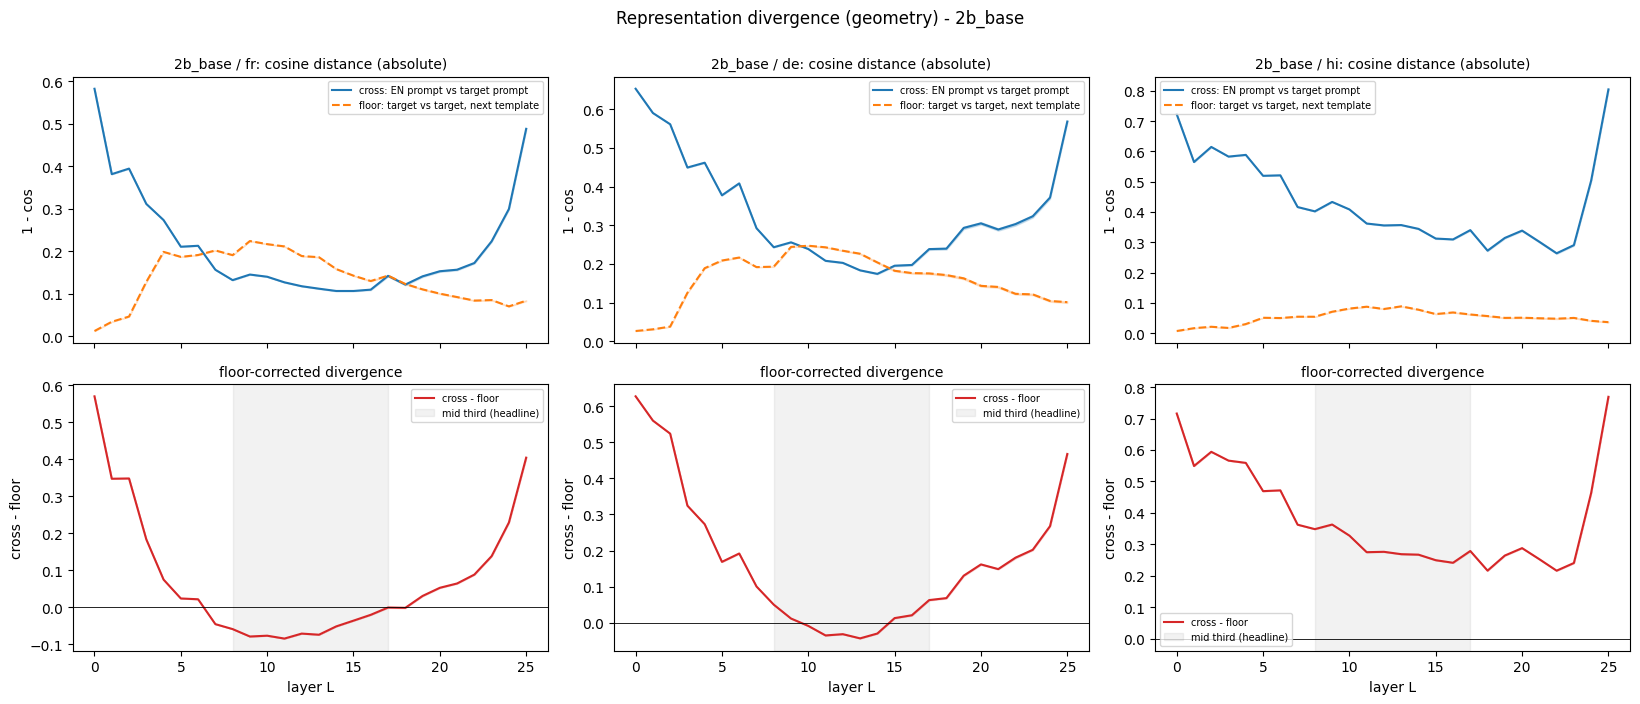

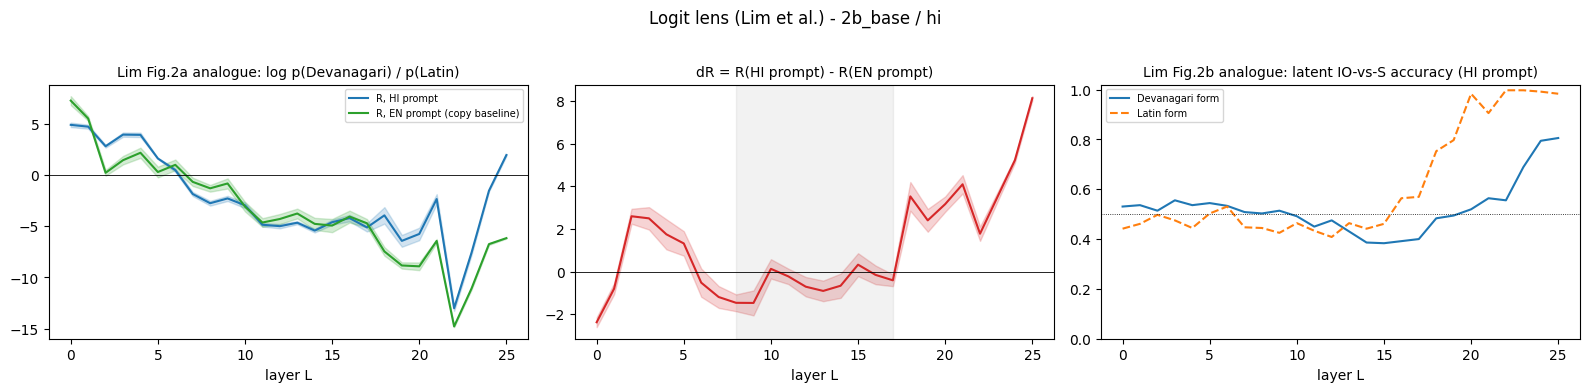

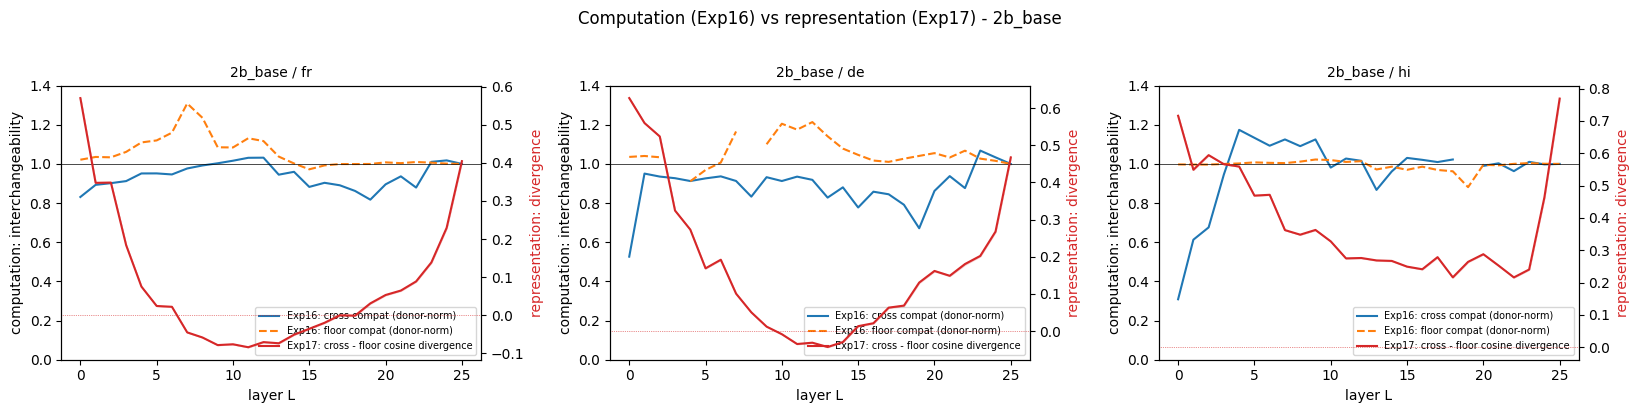

In [13]:
# RUN 1: run the PREFLIGHT cell above first.
MODEL_KEY = "2b_base"
model, tok = load_model(MODEL_KEY)

assert rep_self_test(model, tok), "SELF-TEST FAILED: lens / teacher-forcing pipeline is wrong. STOP and paste the output."

for lang in TARGET_LANGS:
    for seed in SEEDS:
        run_rep(model, tok, MODEL_KEY, lang, seed)

print()
print("=========== 2B SUMMARY ===========")
print_rep_summary(MODEL_KEY)
print_rep_compact([MODEL_KEY])
plot_geometry(MODEL_KEY)
plot_lens(MODEL_KEY)
plot_comp_vs_rep(MODEL_KEY)
free_model(model)

## RUN 2: 9B base, 9B-it (27B-it commented out)

[load] 9b_base  <-  /home/models/gemma-2-9b


Loading weights: 100%|██████████| 464/464 [00:01<00:00, 256.02it/s]


[load] ready in 3.1s  n_layers=42  d_model=3584
  [1] capture vs hidden_states, L=  0: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 21: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 40: rel max diff = 0.00e+00  (informational)
  [2] lens@final layer vs model output: TV distance = 0.0228, same top-1 = True  -> ok=True
  [3] teacher-forced logp(IO) = -2.955 vs real next-token logp(IO) = -3.005  -> ok=True
[9b_base fr s0] 20/120  15.74 pairs/s  eta=6s
[9b_base fr s0] 40/120  15.71 pairs/s  eta=5s
[9b_base fr s0] 60/120  15.73 pairs/s  eta=4s
[9b_base fr s0] 80/120  15.74 pairs/s  eta=3s
[9b_base fr s0] 100/120  15.75 pairs/s  eta=1s
[9b_base fr s0] 120/120  15.76 pairs/s  eta=0s
[run_rep] wrote 9b_base_fr_s0.json + 9b_base_fr_s0.npz
[9b_base fr s7] 20/120  15.84 pairs/s  eta=6s
[9b_base fr s7] 40/120  15.82 pairs/s  eta=5s
[9b_base fr s7] 60/120  15.88 pairs/s  eta=4s
[9b_base fr s7] 80/120  15.91 pairs/s  eta=3s
[9b_base fr s7]

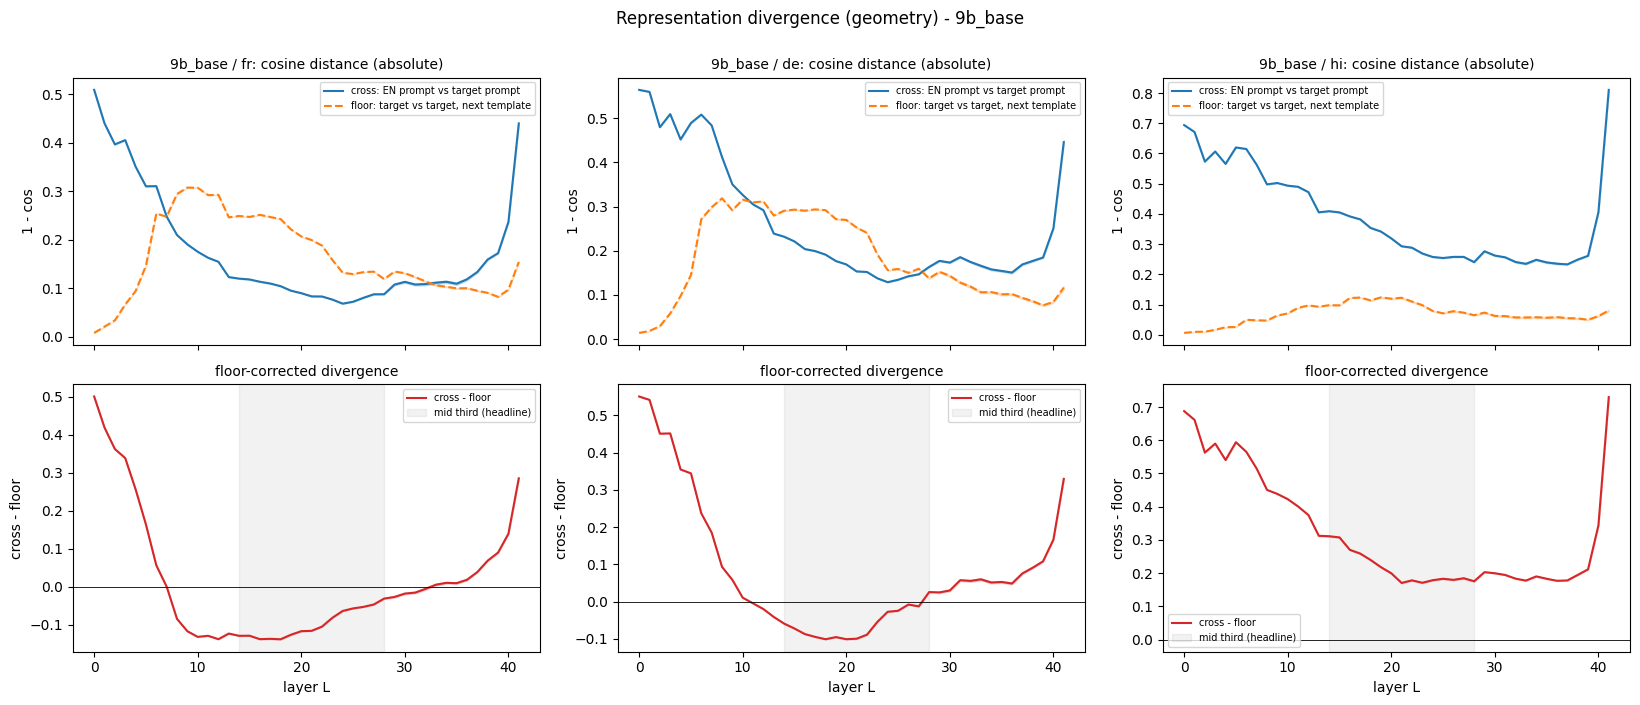

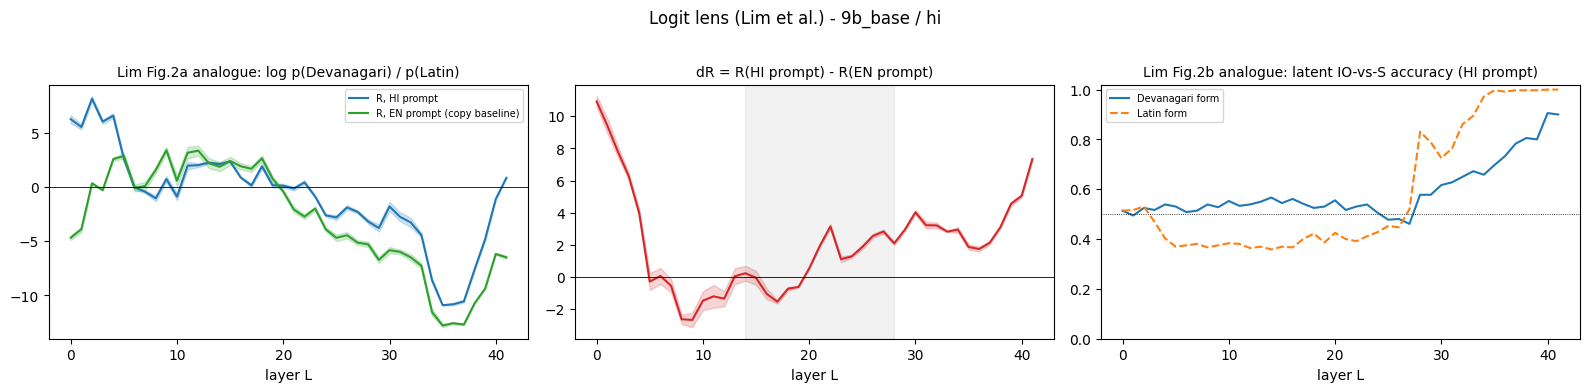

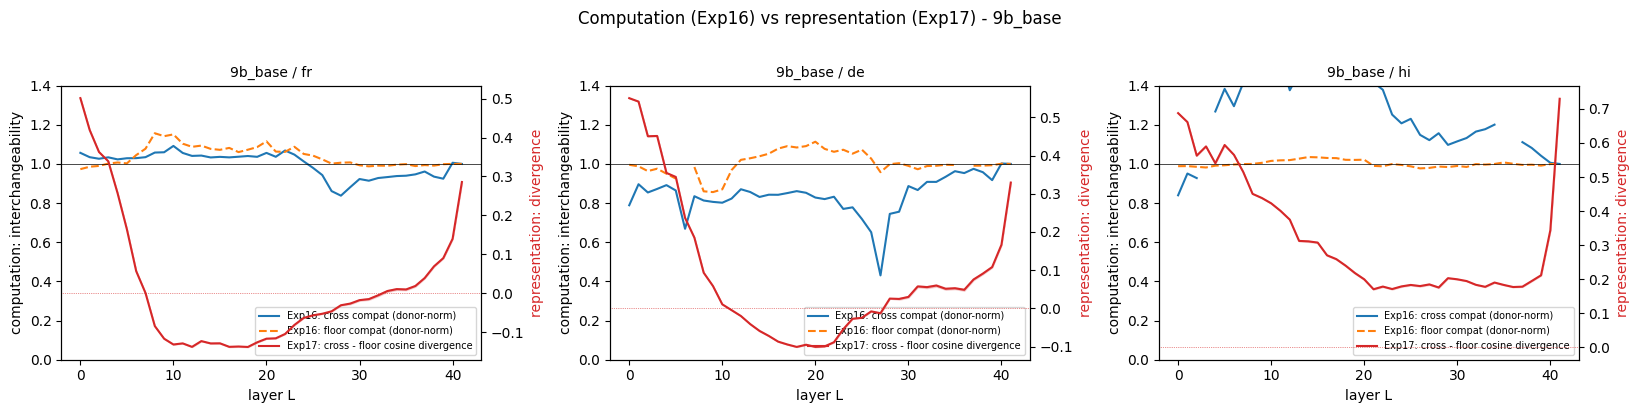

[load] 9b_it  <-  /home/models/gemma-2-9b-it


Loading weights: 100%|██████████| 464/464 [00:02<00:00, 213.85it/s]


[load] ready in 3.2s  n_layers=42  d_model=3584
  [1] capture vs hidden_states, L=  0: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 21: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 40: rel max diff = 0.00e+00  (informational)
  [2] lens@final layer vs model output: TV distance = 0.0117, same top-1 = True  -> ok=True
  [3] teacher-forced logp(IO) = -4.868 vs real next-token logp(IO) = -4.857  -> ok=True
[9b_it fr s0] 20/120  15.73 pairs/s  eta=6s
[9b_it fr s0] 40/120  15.71 pairs/s  eta=5s
[9b_it fr s0] 60/120  15.71 pairs/s  eta=4s
[9b_it fr s0] 80/120  15.74 pairs/s  eta=3s
[9b_it fr s0] 100/120  15.75 pairs/s  eta=1s
[9b_it fr s0] 120/120  15.78 pairs/s  eta=0s
[run_rep] wrote 9b_it_fr_s0.json + 9b_it_fr_s0.npz
[9b_it fr s7] 20/120  15.90 pairs/s  eta=6s
[9b_it fr s7] 40/120  15.89 pairs/s  eta=5s
[9b_it fr s7] 60/120  15.90 pairs/s  eta=4s
[9b_it fr s7] 80/120  15.91 pairs/s  eta=3s
[9b_it fr s7] 100/120  15.92 pairs/s  e

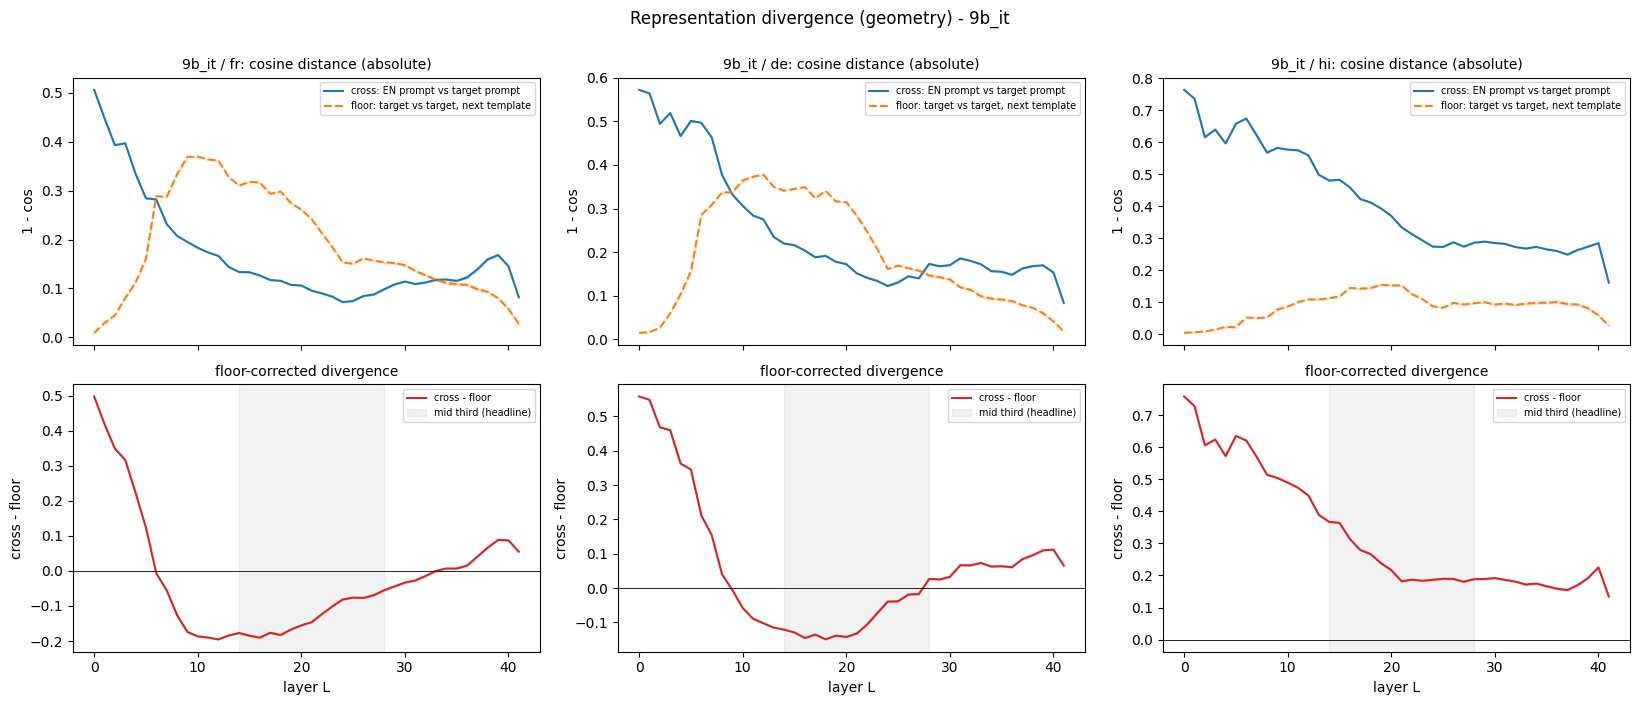

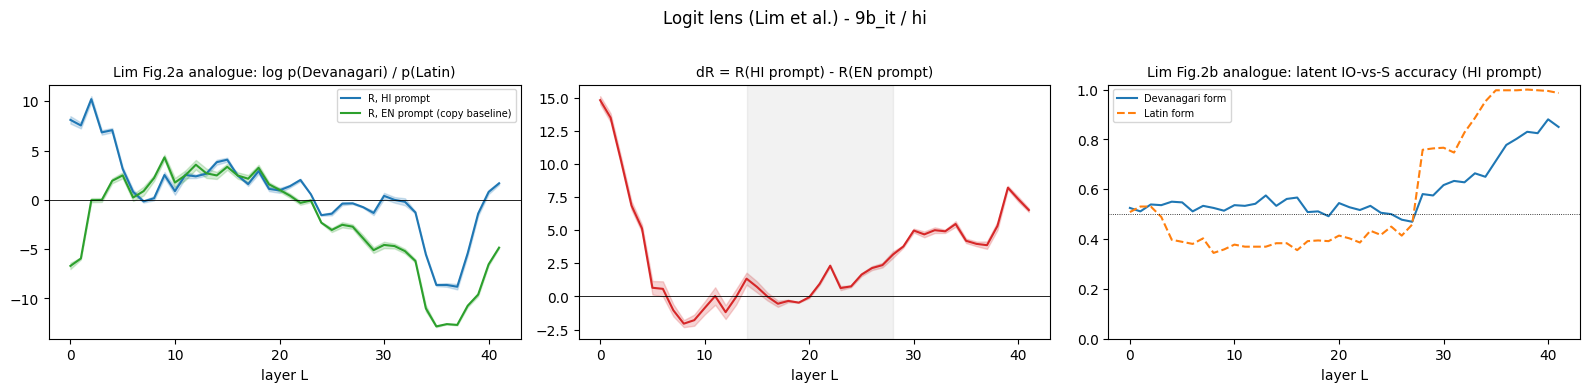

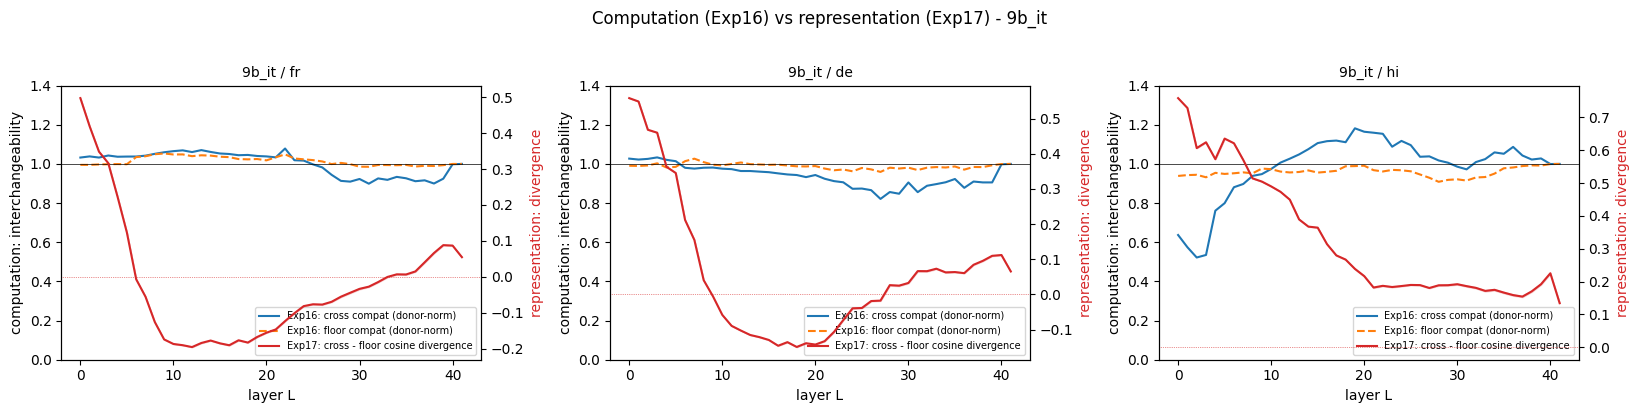


=========== CROSS-SCALE SUMMARY ===========

model    lang   nL  mid-third corrected cos-div (mean+-std over seeds)   cross/floor      mid dR (HI lens)
2b_base  fr     26  -0.0553+-0.0002                                             0.69                   n/a
2b_base  de     26  +0.0012+-0.0001                                             1.01                   n/a
2b_base  hi     26  +0.2895+-0.0005                                             4.97       -0.5497+-0.4443
9b_base  fr     42  -0.0980+-0.0003                                             0.49                   n/a
9b_base  de     42  -0.0598+-0.0005                                             0.74                   n/a
9b_base  hi     42  +0.2151+-0.0014                                             3.16       +0.9133+-0.1359
9b_it    fr     42  -0.1308+-0.0005                                             0.44                   n/a
9b_it    de     42  -0.0908+-0.0007                                             0.65              

In [14]:
# RUN 2: only after RUN 1 looks sane. Cached per (model, lang, seed): safe to interrupt and restart.
for MODEL_KEY in ["9b_base", "9b_it"]:          # , "27b_it"   <- commented out: hours; also uncomment in MODEL_SPECS
    model, tok = load_model(MODEL_KEY)
    assert rep_self_test(model, tok), f"SELF-TEST FAILED on {MODEL_KEY}"
    for lang in TARGET_LANGS:
        for seed in SEEDS:
            run_rep(model, tok, MODEL_KEY, lang, seed)
    print()
    print(f"=========== {MODEL_KEY} SUMMARY ===========")
    print_rep_summary(MODEL_KEY)
    plot_geometry(MODEL_KEY)
    plot_lens(MODEL_KEY)
    plot_comp_vs_rep(MODEL_KEY)
    free_model(model)

print()
print("=========== CROSS-SCALE SUMMARY ===========")
print_rep_compact()

[load] 27b_it  <-  /home/models/gemma-2-27b-it


Loading weights: 100%|██████████| 508/508 [00:37<00:00, 13.52it/s]


[load] ready in 39.1s  n_layers=46  d_model=4608
  [1] capture vs hidden_states, L=  0: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 23: rel max diff = 0.00e+00  (informational)
  [1] capture vs hidden_states, L= 44: rel max diff = 0.00e+00  (informational)
  [2] lens@final layer vs model output: TV distance = 0.0118, same top-1 = True  -> ok=True
  [3] teacher-forced logp(IO) = -3.005 vs real next-token logp(IO) = -2.967  -> ok=True
[27b_it fr s0] 20/120  11.44 pairs/s  eta=9s
[27b_it fr s0] 40/120  11.39 pairs/s  eta=7s
[27b_it fr s0] 60/120  11.40 pairs/s  eta=5s
[27b_it fr s0] 80/120  11.42 pairs/s  eta=4s
[27b_it fr s0] 100/120  11.43 pairs/s  eta=2s
[27b_it fr s0] 120/120  11.42 pairs/s  eta=0s
[run_rep] wrote 27b_it_fr_s0.json + 27b_it_fr_s0.npz
[27b_it fr s7] 20/120  11.51 pairs/s  eta=9s
[27b_it fr s7] 40/120  11.43 pairs/s  eta=7s
[27b_it fr s7] 60/120  11.45 pairs/s  eta=5s
[27b_it fr s7] 80/120  11.48 pairs/s  eta=3s
[27b_it fr s7] 100/120  11

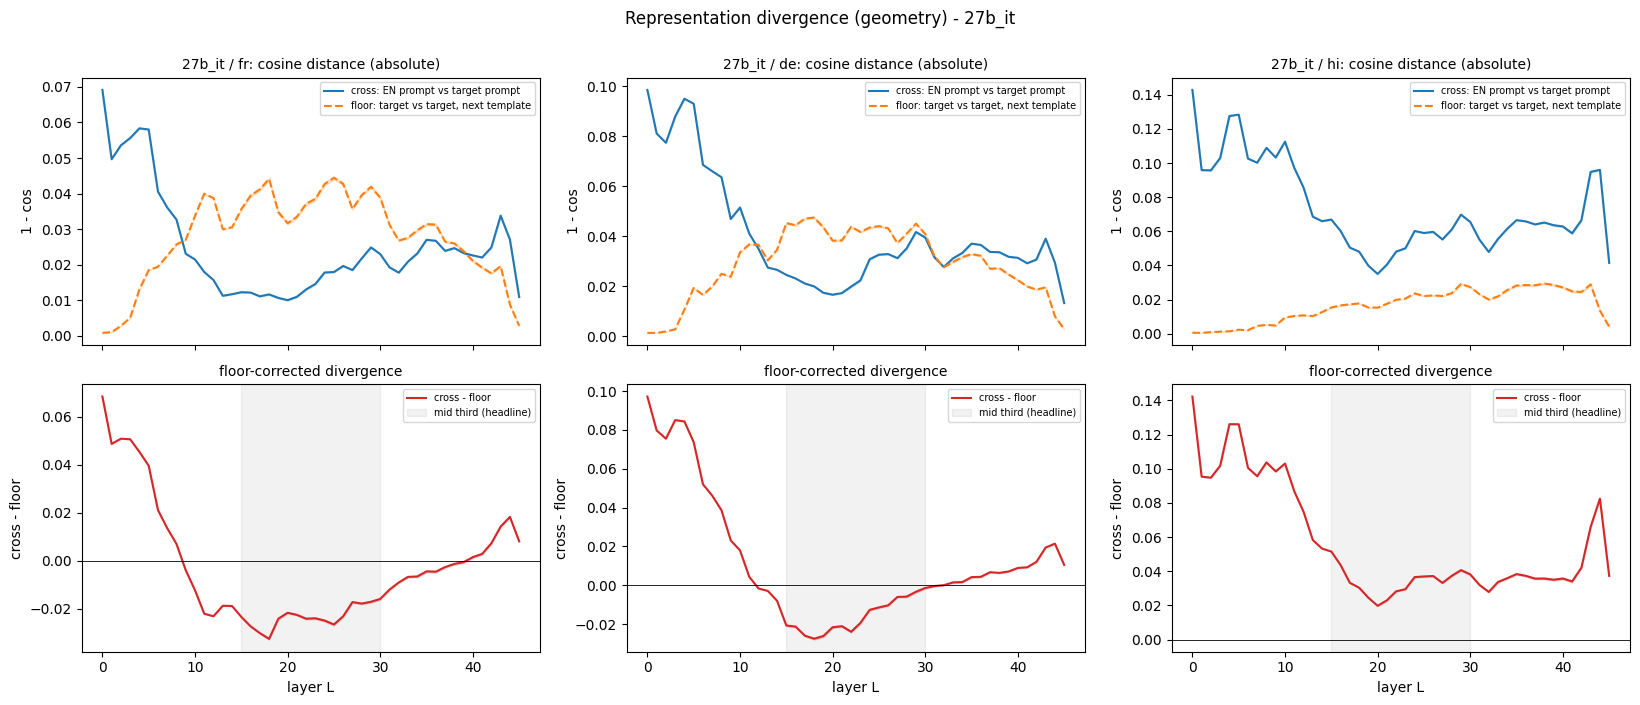

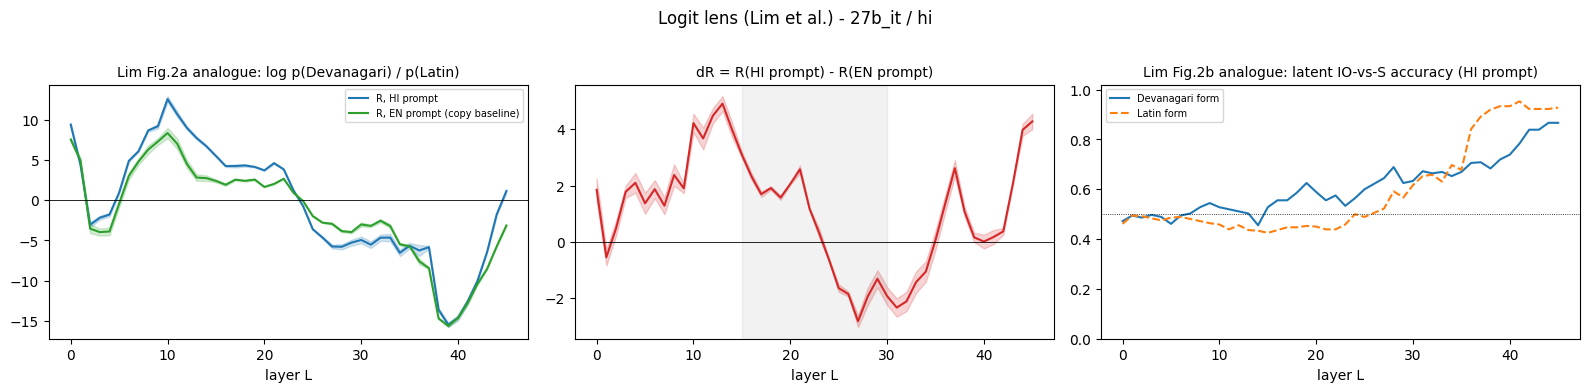

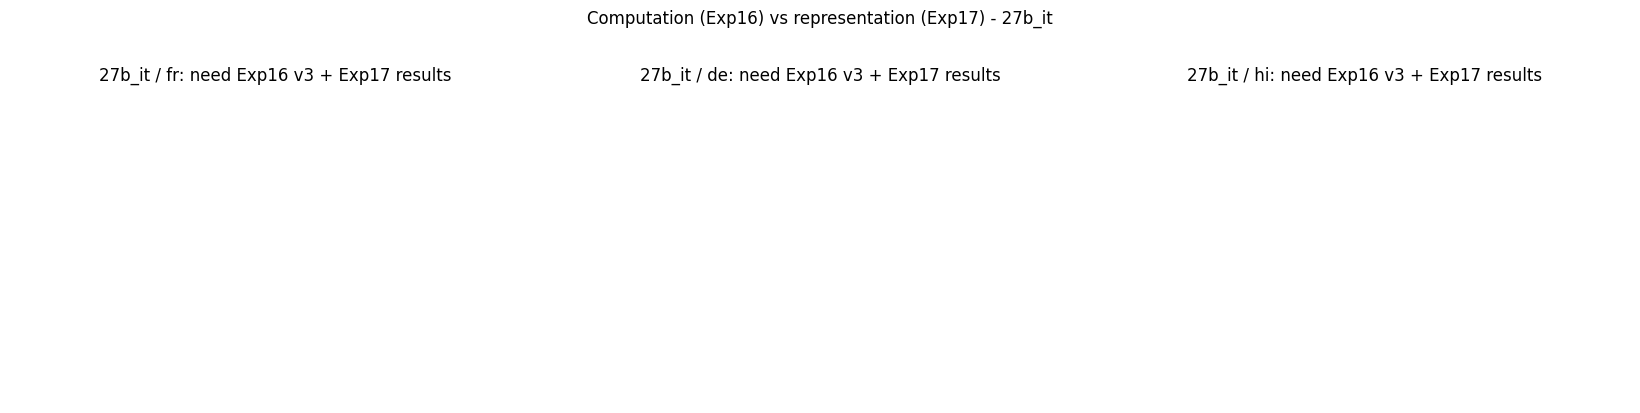


=========== CROSS-SCALE SUMMARY ===========

model    lang   nL  mid-third corrected cos-div (mean+-std over seeds)   cross/floor      mid dR (HI lens)
2b_base  fr     26  -0.0553+-0.0002                                             0.69                   n/a
2b_base  de     26  +0.0012+-0.0001                                             1.01                   n/a
2b_base  hi     26  +0.2895+-0.0005                                             4.97       -0.5497+-0.4443
9b_base  fr     42  -0.0980+-0.0003                                             0.49                   n/a
9b_base  de     42  -0.0598+-0.0005                                             0.74                   n/a
9b_base  hi     42  +0.2151+-0.0014                                             3.16       +0.9133+-0.1359
9b_it    fr     42  -0.1308+-0.0005                                             0.44                   n/a
9b_it    de     42  -0.0908+-0.0007                                             0.65              

In [16]:
# RUN 2: only after RUN 1 looks sane. Cached per (model, lang, seed): safe to interrupt and restart.
MODEL_SPECS = {
    "2b_base": "google/gemma-2-2b",        # no local folder on this machine; HF hub id
    "9b_base": "/home/models/gemma-2-9b",
    "9b_it":   "/home/models/gemma-2-9b-it",
    "27b_it":  "/home/models/gemma-2-27b-it",   # COMMENTED OUT: hours of runtime. Uncomment here AND in RUN 2 to include it.
}
for MODEL_KEY in ["27b_it"]:          # , "27b_it"   <- commented out: hours; also uncomment in MODEL_SPECS
    model, tok = load_model(MODEL_KEY)
    assert rep_self_test(model, tok), f"SELF-TEST FAILED on {MODEL_KEY}"
    for lang in TARGET_LANGS:
        for seed in SEEDS:
            run_rep(model, tok, MODEL_KEY, lang, seed)
    print()
    print(f"=========== {MODEL_KEY} SUMMARY ===========")
    print_rep_summary(MODEL_KEY)
    plot_geometry(MODEL_KEY)
    plot_lens(MODEL_KEY)
    plot_comp_vs_rep(MODEL_KEY)
    free_model(model)

print()
print("=========== CROSS-SCALE SUMMARY ===========")
print_rep_compact()

[load] 2b_base  <-  google/gemma-2-2b


Loading weights: 100%|██████████| 288/288 [00:00<00:00, 765.52it/s]


[load] ready in 3.0s  n_layers=26  d_model=2304
[collect] 2b_base fr: 120 pairs
[collect] 2b_base de: 120 pairs
[collect] 2b_base hi: 120 pairs
[check] raw cross cosine vs saved Exp17 (fr, seed 0): max abs diff = 1.99e-07  OK
[check] raw cross cosine vs saved Exp17 (de, seed 0): max abs diff = 1.38e-07  OK
[check] raw cross cosine vs saved Exp17 (hi, seed 0): max abs diff = 3.00e-07  OK

=== 2b_base: anisotropy diagnostics (pooled over all prompts and languages) ===
  Lim l                              :      2       6      10      14      18      22      26
  share of ||h||^2 in top-5 coords    :  0.313   0.320   0.415   0.454   0.447   0.461   0.294
  mean cosine, distinct prompts      :  0.567   0.603   0.662   0.718   0.716   0.724   0.477
  (a high mean cosine means raw cosine is compressed into a narrow cone; share ~ top-k/d means no rogue dims)

=== 2b_base: floor-corrected divergence, middle third (L 8-17) ===
  geometry    lang mean +- SE (pairs)     cross/floor templates +  s

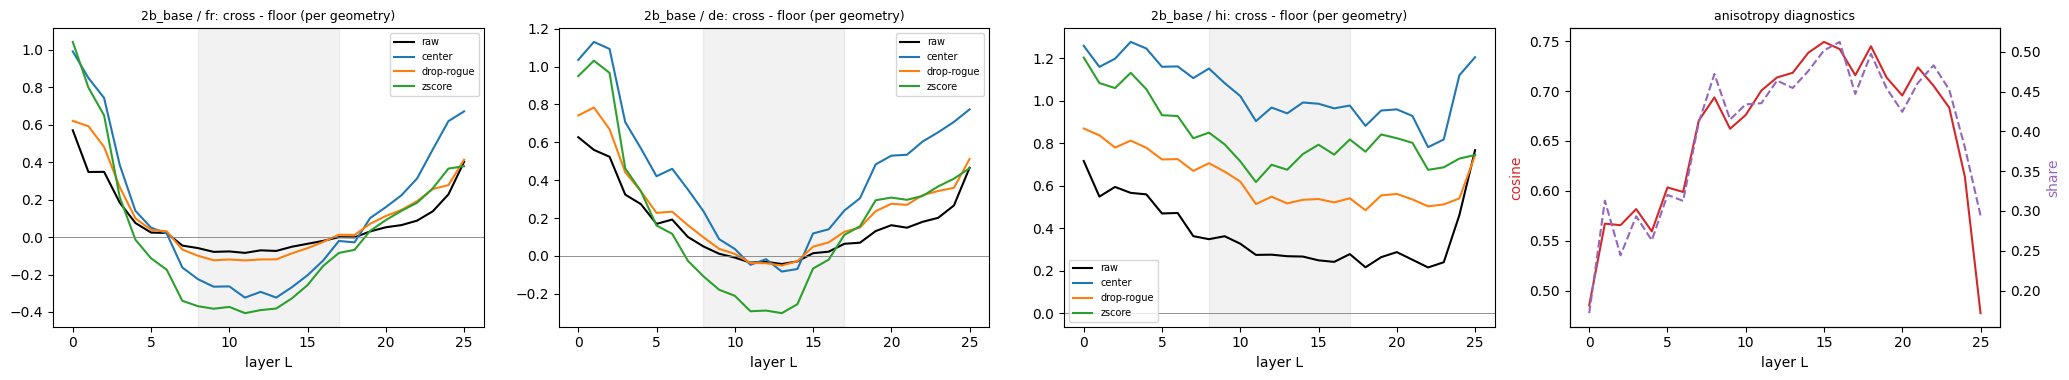

[load] 9b_base  <-  /home/models/gemma-2-9b


Loading weights: 100%|██████████| 464/464 [00:06<00:00, 76.14it/s] 


[load] ready in 7.4s  n_layers=42  d_model=3584
[collect] 9b_base fr: 120 pairs
[collect] 9b_base de: 120 pairs
[collect] 9b_base hi: 120 pairs
[check] raw cross cosine vs saved Exp17 (fr, seed 0): max abs diff = 1.17e-07  OK
[check] raw cross cosine vs saved Exp17 (de, seed 0): max abs diff = 1.36e-07  OK
[check] raw cross cosine vs saved Exp17 (hi, seed 0): max abs diff = 2.26e-07  OK

=== 9b_base: anisotropy diagnostics (pooled over all prompts and languages) ===
  Lim l                              :      2       6      10      14      18      22      26      30      34      38      42
  share of ||h||^2 in top-5 coords    :  0.181   0.188   0.255   0.369   0.434   0.533   0.602   0.504   0.582   0.591   0.255
  mean cosine, distinct prompts      :  0.528   0.537   0.578   0.658   0.676   0.742   0.796   0.750   0.786   0.769   0.448
  (a high mean cosine means raw cosine is compressed into a narrow cone; share ~ top-k/d means no rogue dims)

=== 9b_base: floor-corrected divergence

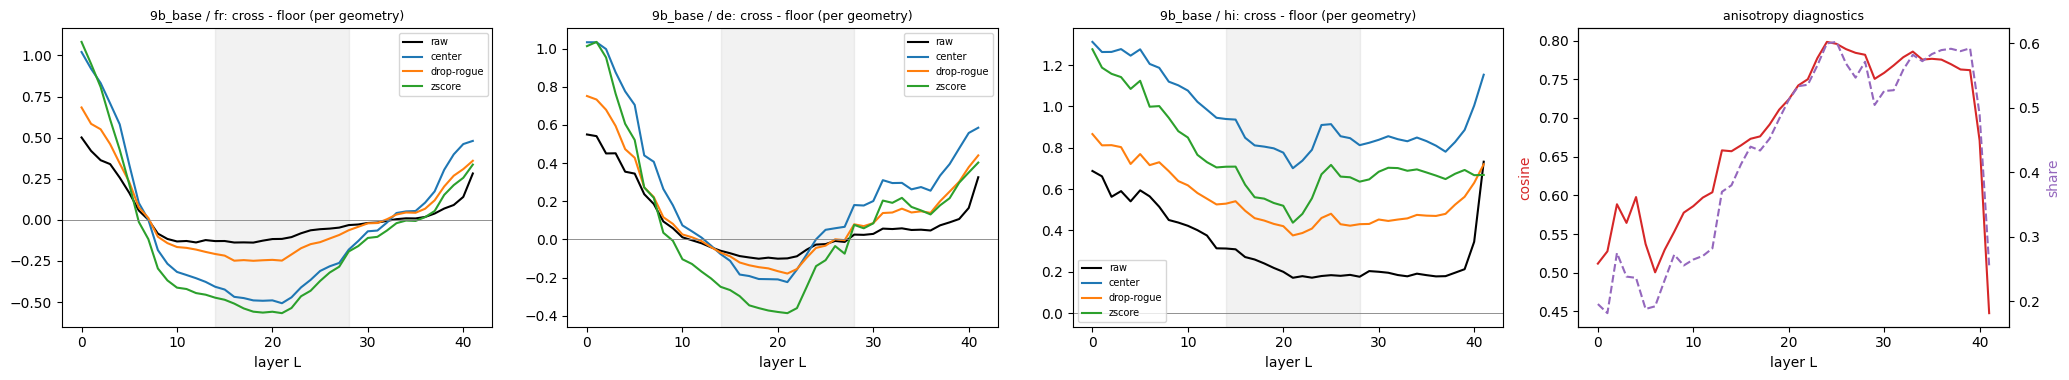

[load] 9b_it  <-  /home/models/gemma-2-9b-it


Loading weights: 100%|██████████| 464/464 [00:02<00:00, 195.91it/s]


[load] ready in 3.4s  n_layers=42  d_model=3584
[collect] 9b_it fr: 120 pairs
[collect] 9b_it de: 120 pairs
[collect] 9b_it hi: 120 pairs
[check] raw cross cosine vs saved Exp17 (fr, seed 0): max abs diff = 9.74e-08  OK
[check] raw cross cosine vs saved Exp17 (de, seed 0): max abs diff = 8.34e-08  OK
[check] raw cross cosine vs saved Exp17 (hi, seed 0): max abs diff = 2.67e-07  OK

=== 9b_it: anisotropy diagnostics (pooled over all prompts and languages) ===
  Lim l                              :      2       6      10      14      18      22      26      30      34      38      42
  share of ||h||^2 in top-5 coords    :  0.162   0.182   0.177   0.260   0.371   0.477   0.580   0.481   0.544   0.565   0.837
  mean cosine, distinct prompts      :  0.507   0.524   0.531   0.591   0.645   0.709   0.785   0.744   0.764   0.751   0.874
  (a high mean cosine means raw cosine is compressed into a narrow cone; share ~ top-k/d means no rogue dims)

=== 9b_it: floor-corrected divergence, middle t

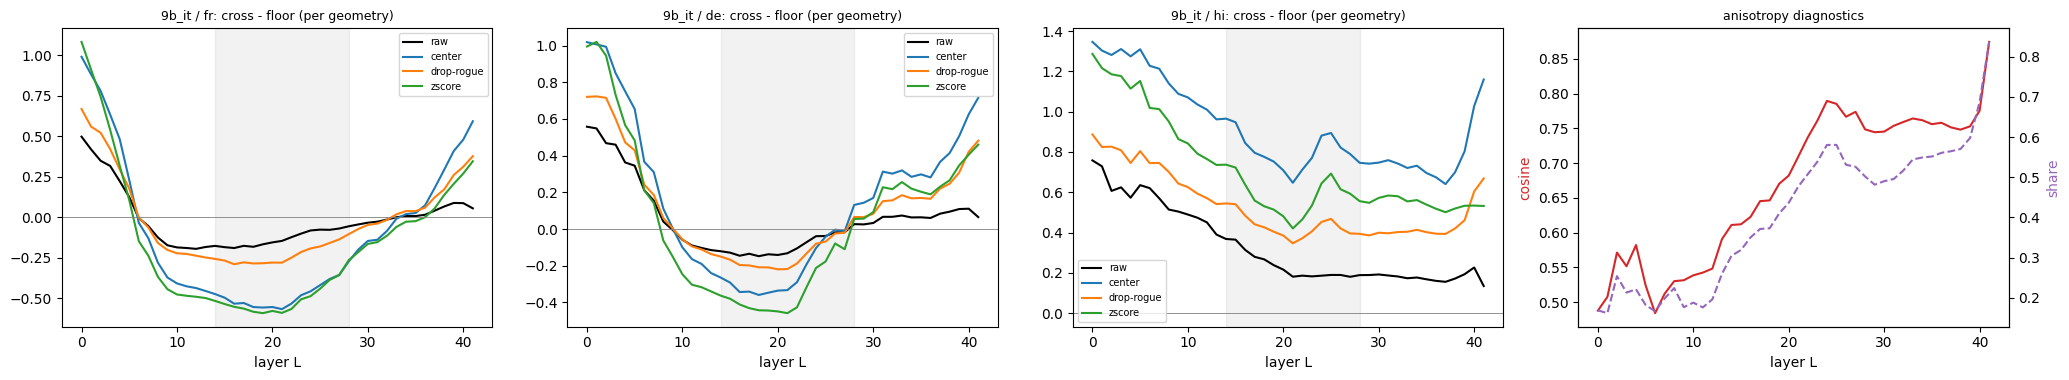

[load] 27b_it  <-  /home/models/gemma-2-27b-it


Loading weights: 100%|██████████| 508/508 [00:06<00:00, 78.28it/s] 


[load] ready in 8.5s  n_layers=46  d_model=4608
[collect] 27b_it fr: 120 pairs
[collect] 27b_it de: 120 pairs
[collect] 27b_it hi: 120 pairs
[check] raw cross cosine vs saved Exp17 (fr, seed 0): max abs diff = 8.94e-09  OK
[check] raw cross cosine vs saved Exp17 (de, seed 0): max abs diff = 2.68e-08  OK
[check] raw cross cosine vs saved Exp17 (hi, seed 0): max abs diff = 3.38e-08  OK

=== 27b_it: anisotropy diagnostics (pooled over all prompts and languages) ===
  Lim l                              :      2       6      10      14      18      22      26      30      34      38      42      46
  share of ||h||^2 in top-5 coords    :  0.876   0.788   0.846   0.912   0.921   0.932   0.902   0.882   0.914   0.907   0.914   0.975
  mean cosine, distinct prompts      :  0.937   0.915   0.935   0.950   0.950   0.960   0.943   0.935   0.952   0.946   0.947   0.974
  (a high mean cosine means raw cosine is compressed into a narrow cone; share ~ top-k/d means no rogue dims)

=== 27b_it: floor-c

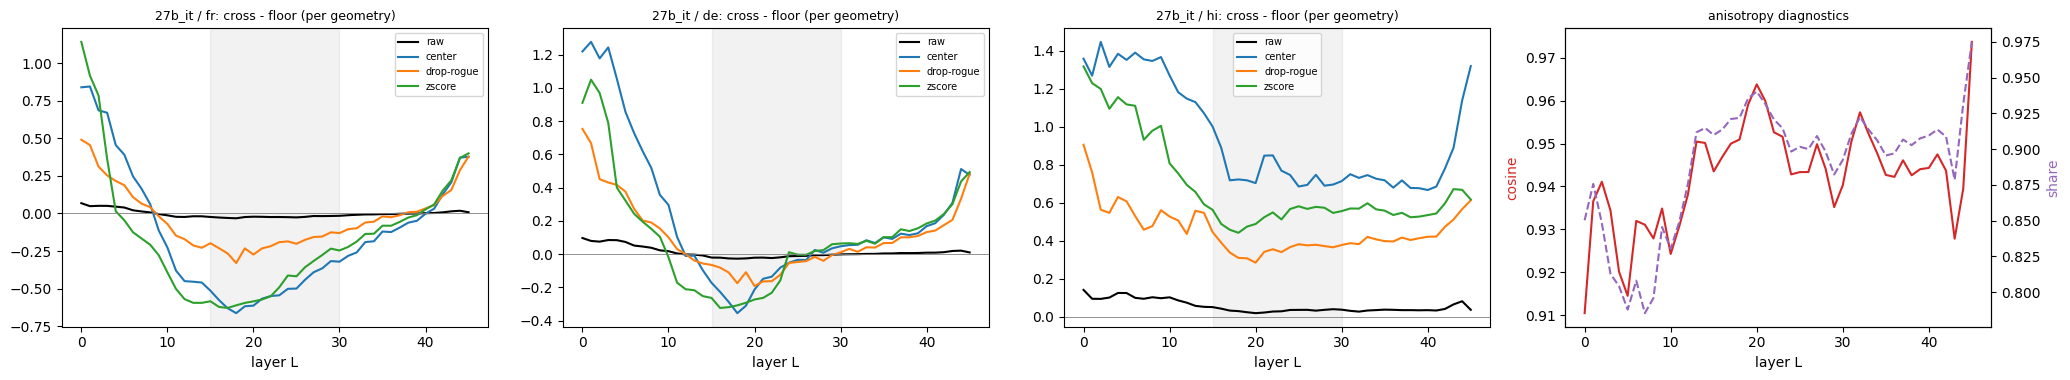

In [17]:
# %% CELL 1: anisotropy check. Paste into the Exp17 notebook AFTER its config / prompt / helper cells have run
# (needs: load_model, free_model, build_pairs, capture_residuals, _np, mid_slice, lim_layers, rep_paths, ...).
#
# Question: are the Exp17 cosine results (FR/DE below the floor, HI above it) an artifact of anisotropy, i.e. a few
# huge residual-stream coordinates dominating raw cosine? Four geometries are compared on the SAME states:
#   raw         : the Exp17 measure (sanity: must reproduce the saved Exp17 numbers)
#   center      : subtract ONE global mean per layer (pooled over all prompts/languages). NOT per-language, so any
#                 genuine language offset survives.
#   drop-rogue  : zero the K coordinates with the largest mean squared value (per layer), no centering
#   zscore      : global centering + per-coordinate standardisation
# Only the SIGN PATTERN and the cross/floor ratio are comparable across geometries (magnitudes are not).
#
# Pre-specified criterion (fixed before any result): "robust" if, in the middle third of the stack, every geometry gives
# the same sign pattern as raw for (FR, DE, HI). Sign is + / - only if mean -/+ 2 SE excludes 0, else 0 (SE over pairs).

_needed = ["load_model", "free_model", "build_pairs", "capture_residuals", "_np", "TARGET_LANGS", "SEEDS",
           "N_PROMPTS", "mid_slice", "lim_layers", "rep_paths", "REP_VERSION", "np", "plt", "json"]
_missing = [n for n in _needed if n not in globals()]
assert not _missing, f"Run the Exp17 notebook cells first (config, prompts, helpers). Missing: {_missing}"

ANISO_K = 5
ANISO_VARIANTS = ["raw", "center", "drop-rogue", "zscore"]


def _cosd(A, B):
    num = (A * B).sum(-1)
    den = np.linalg.norm(A, axis=-1) * np.linalg.norm(B, axis=-1) + 1e-12
    return 1.0 - num / den                                              # [N, n_layers]


def _collect(model, tok, lang, seed, n_prompts, en_cache):
    """Final-position residuals [N, n_layers, d] for target / EN-donor / floor-donor prompts of one (lang, seed)."""
    pairs = build_pairs(tok, lang, n_prompts, seed)
    last = lambda prompt: _np(capture_residuals(model, tok(prompt)["input_ids"])[:, -1, :])
    T = np.stack([last(p["target_prompt"]) for p in pairs])
    F = np.stack([last(p["donor_floor"]) for p in pairs])
    en_prompts = tuple(p["donor_cross"] for p in pairs)
    if seed in en_cache and en_cache[seed][0] == en_prompts:           # EN prompts are identical across languages
        E = en_cache[seed][1]
    else:
        E = np.stack([last(p) for p in en_prompts])
        en_cache[seed] = (en_prompts, E)
    return T, E, F, np.array([p["template_idx"] for p in pairs]), en_prompts


def _pool_stats(groups, k):
    X = np.concatenate(groups, axis=0)                                  # [M, n, d]
    mu = X.mean(0)
    sd = X.std(0)
    sd = sd + 1e-3 * sd.mean(-1, keepdims=True)
    energy = (X ** 2).mean(0)                                           # [n, d]
    rogue = np.argsort(-energy, axis=-1)[:, :k]                         # [n, k]
    share = np.take_along_axis(energy, rogue, axis=-1).sum(-1) / energy.sum(-1)
    U = X / (np.linalg.norm(X, axis=-1, keepdims=True) + 1e-12)
    S, M = U.sum(0), X.shape[0]
    mean_cos = ((S ** 2).sum(-1) - M) / (M * (M - 1))                   # mean cosine between distinct states
    return mu, sd, rogue, share, mean_cos


def _apply(X, kind, mu, sd, rogue):
    if kind == "raw":
        return X
    if kind == "center":
        return X - mu[None]
    if kind == "zscore":
        return (X - mu[None]) / sd[None]
    if kind == "drop-rogue":
        Y = X.copy()
        for l in range(Y.shape[1]):
            Y[:, l, rogue[l]] = 0.0
        return Y
    raise ValueError(kind)


def _sgn(mean, se):
    return "+" if mean - 2 * se > 0 else ("-" if mean + 2 * se < 0 else "0")


def anisotropy_check(model_key, seeds=(0,), n_prompts=N_PROMPTS, k=ANISO_K):
    model, tok = load_model(model_key)
    n = model.config.num_hidden_layers
    data, en_cache, tmpl = {}, {}, {}
    for lang in TARGET_LANGS:
        Ts, Es, Fs, Ms, ens = [], [], [], [], []
        for seed in seeds:
            T, E, F, tm, en_p = _collect(model, tok, lang, seed, n_prompts, en_cache)
            Ts.append(T); Es.append(E); Fs.append(F); Ms.append(tm); ens.append(en_p)
        data[lang] = (np.concatenate(Ts), np.concatenate(Es), np.concatenate(Fs), tuple(ens))
        tmpl[lang] = np.concatenate(Ms)
        print(f"[collect] {model_key} {lang}: {len(data[lang][0])} pairs")
    free_model(model)

    # pool: every distinct EN prompt set once, plus target and floor states of each language
    groups, seen = [], set()
    for lang in TARGET_LANGS:
        T, E, F, ens = data[lang]
        if ens not in seen:
            seen.add(ens); groups.append(E)
        groups += [T, F]
    mu, sd, rogue, share, mean_cos = _pool_stats(groups, k)

    res = {v: {} for v in ANISO_VARIANTS}
    for v in ANISO_VARIANTS:
        for lang in TARGET_LANGS:
            T, E, F, _ = data[lang]
            Tt, Et, Ft = (_apply(X, v, mu, sd, rogue) for X in (T, E, F))
            cc, cf = _cosd(Et, Tt), _cosd(Ft, Tt)
            res[v][lang] = {"cross": cc.mean(0), "floor": cf.mean(0), "corr": cc - cf}

    # sanity: the raw geometry must reproduce the saved Exp17 numbers for the first seed
    for lang in TARGET_LANGS:
        jp, _ = rep_paths(model_key, lang, seeds[0])
        if jp.exists():
            saved = np.array(json.load(open(jp))["cos_cross"])
            mine = _cosd(data[lang][1][:n_prompts], data[lang][0][:n_prompts]).mean(0)
            d = float(np.abs(saved - mine).max())
            print(f"[check] raw cross cosine vs saved Exp17 ({lang}, seed {seeds[0]}): max abs diff = {d:.2e}  "
                  f"{'OK' if d < 1e-3 else 'MISMATCH: this notebook is not measuring what Exp17 measured'}")
        else:
            print(f"[check] no saved Exp17 result for {model_key}/{lang} seed {seeds[0]}: raw check skipped")

    ms = mid_slice(n)
    print()
    print(f"=== {model_key}: anisotropy diagnostics (pooled over all prompts and languages) ===")
    Ls = lim_layers(n)
    print("  Lim l                              : " + "  ".join(f"{L + 1:>6d}" for L in Ls))
    print(f"  share of ||h||^2 in top-{k} coords    : " + "  ".join(f"{share[L]:6.3f}" for L in Ls))
    print("  mean cosine, distinct prompts      : " + "  ".join(f"{mean_cos[L]:6.3f}" for L in Ls))
    print("  (a high mean cosine means raw cosine is compressed into a narrow cone; share ~ top-k/d means no rogue dims)")

    print()
    print(f"=== {model_key}: floor-corrected divergence, middle third (L {ms.start}-{ms.stop - 1}) ===")
    print(f"  {'geometry':<11s} {'lang':<4s} {'mean +- SE (pairs)':<22s} {'cross/floor':>11s} {'templates +':>11s}  sign")
    signs = {v: {} for v in ANISO_VARIANTS}
    for v in ANISO_VARIANTS:
        for lang in TARGET_LANGS:
            r = res[v][lang]
            per_pair = r["corr"][:, ms].mean(axis=1)
            m, se = float(per_pair.mean()), float(per_pair.std() / np.sqrt(len(per_pair)))
            ratio = r["cross"][ms].mean() / max(r["floor"][ms].mean(), 1e-9)
            tm = tmpl[lang]
            npos = sum(int(per_pair[tm == t].mean() > 0) for t in range(6))
            signs[v][lang] = _sgn(m, se)
            print(f"  {v:<11s} {lang:<4s} {m:+.4f} +- {se:.4f}      {ratio:>11.2f} {npos:>9d}/6  {signs[v][lang]}")
    print()
    raw_pat = tuple(signs["raw"][l] for l in TARGET_LANGS)
    for v in ANISO_VARIANTS[1:]:
        pat = tuple(signs[v][l] for l in TARGET_LANGS)
        print(f"  {v:<11s} sign pattern {dict(zip(TARGET_LANGS, pat))}  vs raw {dict(zip(TARGET_LANGS, raw_pat))}  ->  "
              f"{'SAME (robust to this geometry)' if pat == raw_pat else 'DIFFERENT (raw result depends on anisotropy)'}")

    fig, axes = plt.subplots(1, len(TARGET_LANGS) + 1, figsize=(5.2 * (len(TARGET_LANGS) + 1), 3.9))
    Lx = np.arange(n)
    for ax, lang in zip(axes, TARGET_LANGS):
        for v, col in zip(ANISO_VARIANTS, ("k", "C0", "C1", "C2")):
            ax.plot(Lx, res[v][lang]["corr"].mean(0), color=col, label=v)
        ax.axhline(0, color="gray", lw=0.6)
        ax.axvspan(ms.start, ms.stop - 1, color="gray", alpha=0.10)
        ax.set_title(f"{model_key} / {lang}: cross - floor (per geometry)", fontsize=9)
        ax.set_xlabel("layer L"); ax.legend(fontsize=7)
    ax = axes[-1]
    ax.plot(Lx, mean_cos, color="C3", label="mean cosine, distinct prompts")
    ax.set_ylabel("cosine", color="C3"); ax.set_xlabel("layer L")
    ax2 = ax.twinx(); ax2.plot(Lx, share, color="C4", ls="--", label=f"top-{k} coords share of ||h||^2")
    ax2.set_ylabel("share", color="C4")
    ax.set_title("anisotropy diagnostics", fontsize=9)
    plt.tight_layout(); plt.show()
    return res


# %% CELL 2: RUN. 2B first; the loop below does the rest. The pass is forward-only, so it is far cheaper than Exp16.
# (All geometries are computed from the same captured states; seeds=(0,) keeps memory modest. Use seeds=SEEDS for all three.)
_ = anisotropy_check("2b_base")

# %% CELL 3: remaining models (27B included: it is where the floor dropped ~8x, i.e. where compression is most suspect)
for _mk in ["9b_base", "9b_it", "27b_it"]:
    _ = anisotropy_check(_mk)